# ¿Cuánto aviso nos da un río? · 01 — Modelos de caudal con información local: Racarumi (Chancay-Lambayeque)

**Curso:** Ciencia de Datos Ambientales (CDA) · Universidad de Ingeniería y Tecnología (UTEC) · Proyecto Integrador

**Equipo:** 

- Luis Angel Cupe Espinoza
- Yely Lanasca Justiniano 
- Lia Kim Alcantara Tineo 
- Mayra Madelyn Marzano Mejia 
- María Fernanda Torres Carbajal 

**Protocolo:** común a todo el estudio (`comun.py`; identificado como `v4` en el código y en las salidas). La fecha de ejecución y las versiones de software se imprimen en la celda de configuración.

**Lugar en el estudio:** este cuaderno responde la pregunta **P1** —hasta qué horizonte se pronostica bien la magnitud del caudal con la información local de la estación— en Racarumi (Chancay-Lambayeque, vertiente del Pacífico). Forma parte de una secuencia única: Tamshiyacu (02), comparación de estaciones (03), anticipación de crecidas (04), estaciones aguas arriba (05), lluvia de la cuenca (06), Chronos-2 (07), comparación integrada y selección final (08) y síntesis (09).

**Sobre el periodo de prueba:** las reglas de selección se fijaron antes de la evaluación final, pero el periodo de prueba (2016–fin) se consultó durante el desarrollo del proyecto, al decidir qué modelos conservar. Sus cifras se leen como la evaluación de un protocolo congelado, no como una confirmación totalmente independiente.

---

## 0. Objetivo y decisiones de diseño

### 0.1 Pregunta
> **¿Cuál es el horizonte útil del pronóstico diario del caudal de Racarumi y cómo varía entre modelos, periodos y condiciones de caudal?**

**Estación:** Racarumi (PE_200907), salida del Chancay-Lambayeque en la vertiente del Pacífico. El EDA la clasificó como **apta** (42.5 años, 0.32 % de vacíos, homogénea). Su registro en CAMELS-PE termina el 2023-08-31. El EDA estimó que el caudal responde a la lluvia en ~2 días.

### 0.2 Qué se pronostica y con qué
- **Objetivo:** caudal observado diario Q(t + h) en m³/s, para **h = 1 a 30 días**, emitido el día t (pronóstico directo: cada horizonte se estima con la información disponible en t, sin realimentar pronósticos).
- **Entradas:** caudales observados de la propia estación de t − 29 a t (30 días) y la **época del año** (seno y coseno del día del año, información estacional adicional, igual para todos los modelos). Sin precipitación ni caudal simulado.
- **Datos:** serie observada depurada del EDA. Vacíos ≤ 3 días se interpolan **solo en las entradas** y solo entre días observados ≤ t (se exige Q(t) observado); los objetivos nunca se imputan. Una emisión se evalúa solo si sus 30 objetivos están observados: todos los modelos y horizontes usan el mismo conjunto de emisiones.
- **Disponibilidad operativa:** se supone que el caudal medio del día t está disponible al emitir. Un uso real tendría que restar la latencia de publicación.

### 0.3 Protocolo (fijado antes de ver la prueba)
| Paso | Decisión |
|---|---|
| División temporal | Entrenamiento: inicio–2008 · Validación: 2009–2015 · Prueba: 2016–fin. Ningún objetivo de un bloque cruza al siguiente. |
| Preparación sin información futura | ε de log(Q + ε), umbral de escalones, P95 y estandarizaciones se calculan **solo con entrenamiento**; con entrenamiento + validación se reentrena sin recalcularlos. |
| Referencias | Persistencia y climatología del día del año (31 días). La climatología usa los mismos años que el modelo en cada fase. |
| Modelos (6) | Regresión lineal múltiple, Random Forest, XGBoost, KNN, MLP y LSTM, más el **combinado por horizonte**. Todos aprenden el **cambio logarítmico** respecto a hoy. Entradas: 30 días + calendario (la LSTM, como secuencia); **KNN elige con la validación cuántos días usa en la distancia (3, 7, 15 o 30)**. La comparación es entre configuraciones ajustadas por modelo, no entre algoritmos con entradas idénticas. Random Forest y MLP aprenden los objetivos **estandarizados por horizonte** (como la LSTM), para que todos los horizontes pesen lo mismo en su ajuste. |
| Validación en dos bloques | **Calibración 2009–2011** (solo estima la corrección de retransformación de Duan) y **selección 2012–2015** (solo compara candidatos). Ninguna emisión de calibración tiene objetivos en el bloque de selección (separación ≥ 30 días): cada pronóstico comparado usa solo factores estimados con el pasado. |
| Ajuste | Mallas predefinidas (1 a 40 combinaciones por modelo, registradas) evaluadas con el NSE medio de los 30 horizontes en el bloque de selección. Sin particiones aleatorias: XGBoost y MLP sin parada interna; iteraciones y épocas como hiperparámetros. La LSTM se detiene con un bloque **distinto** (2005–2008, entrenando hasta 2004) y luego se reentrena con todo el entrenamiento. |
| Semillas | Random Forest, XGBoost, MLP y LSTM se repiten con 3 semillas predefinidas; el pronóstico es su promedio y se informa la variabilidad entre semillas. |
| Selección (regla fijada antes de evaluar) | 1) Mejor = mayor NSE medio en el bloque de selección. 2) Diferencia de cada candidato con el mejor por bootstrap **pareado** por meses (IC 90 %): **equivalente** si el IC cabe en ±0.01 de NSE, **peor** si queda bajo 0, **inconcluso** en otro caso. 3) **Seleccionado = el más simple** entre el mejor y sus equivalentes (lineal < KNN < Random Forest < XGBoost < MLP < LSTM). Combinado por horizonte: para cada h, el modelo con mejor NSE en ese h en el bloque de selección (no compite: su NSE de selección es optimista por construcción). La prueba no se usa para decidir. |
| Retransformación en prueba | Factor de Duan estimado con los residuos de toda la validación del modelo entrenado hasta 2008 (fuera de muestra y anterior a la prueba) y **transferido** al modelo reentrenado con 2009–2015; no se presume perfecto después del reentrenamiento (la sección 5.3 muestra cuánto cambia la prueba sin él). |
| Métricas (m³/s) | MAE, RMSE, NSE, KGE, PBIAS y **habilidad** = 1 − MSE(modelo)/MSE(referencia). |

### 0.4 Horizonte útil
| Nombre | Definición | Uso |
|---|---|---|
| **H (definición principal)** | Mayor h consecutivo desde 1 con NSE > 0 y habilidad > 0 frente a la persistencia **y** a la climatología. Si h = 1 falla, H = 0 | Se aplica igual a la prueba y a cada réplica bootstrap |
| **H cota 95 %** | min(H, percentil 5 de H en 1 000 réplicas del bootstrap conjunto por bloques de un mes) | **Cifra que se usa en las conclusiones** |
| Distribución de H | Percentiles 5, 50 y 95 y P(H ≥ 30) | Incertidumbre del horizonte completo |
| H marginal estricto | Exige el límite inferior de cada IC 95 % **marginal** > 0 | Complementario; los IC por horizonte no forman una banda simultánea |
| NSE ≥ 0.5 hasta | Mayor h consecutivo con NSE ≥ 0.5 | Complementario; no es una definición de utilidad operativa |

H = 30 significa **"30 o más"**: el límite no se encontró en el rango evaluado. Un horizonte útil para estimar la **magnitud** no implica avisar un **nuevo** cruce del P95 con esa anticipación; eso se evalúa en `04_Anticipacion_Crecidas.ipynb`.

---
## 1. Configuración
Librerías, semillas y rutas relativas. Las funciones de datos, métricas, modelos y verificación están en `comun.py`, de modo que las dos estaciones se modelan exactamente con el mismo método. Antes de modelar se ejecuta `pruebas_protocolo.py` (sin información futura en las entradas ni en la retransformación, bloques sin solape, regla de selección): si una comprobación falla, el cuaderno se detiene.

In [1]:
import os, subprocess, sys, warnings
from datetime import datetime
from pathlib import Path
import json, platform, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, torch, xgboost

import comun as C

%matplotlib inline
warnings.filterwarnings('ignore')
np.random.seed(C.SEMILLA)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

RAPIDO = os.environ.get('CDA_RAPIDO') == '1'          # solo para probar el código: mallas mínimas
if RAPIDO:
    C.MALLAS = {k: {kk: vv[:1] for kk, vv in v.items()} for k, v in C.MALLAS.items()}
    C.SEMILLAS = C.SEMILLAS[:1]
B = 50 if RAPIDO else 1000

ESTACION = 'Racarumi'
RUTA_SAL = C.ruta_salidas() / ESTACION.lower()          # modo rápido: salidas_rapido/ (nunca se mezcla con la ejecución final)
RUTA_FIG, RUTA_TAB = RUTA_SAL / 'figuras', RUTA_SAL / 'tablas'
for r in (RUTA_FIG, RUTA_TAB):
    r.mkdir(parents=True, exist_ok=True)

L = C.L_VENTANA
H = len(C.HORIZONTES)
H_CLAVE = [1, 2, 3, 5, 7, 10, 15, 20, 30]
MODELOS = list(C.MODELOS)
COMB = C.COMB
COLOR = C.COLOR
FUENTE = 'Fuente: CAMELS-PE v1.0.1 (SENAMHI), caudal observado depurado del EDA'
T_INICIO = time.time()

print(f"Ejecutado: {datetime.now():%Y-%m-%d %H:%M} | protocolo {C.VERSION}" + (' | MODO RÁPIDO (no usar sus cifras)' if RAPIDO else ''))
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"xgboost {xgboost.__version__} | torch {torch.__version__}")
C.asegurar_camels(); print('CAMELS-PE disponible')
# Comprobaciones automáticas del protocolo (información futura, bloques, regla de selección): se detiene si alguna falla
print(subprocess.run([sys.executable, 'pruebas_protocolo.py'], capture_output=True, text=True, check=True).stdout.splitlines()[-1])

Ejecutado: 2026-11-18 02:07 | protocolo v4
Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | xgboost 3.1.2 | torch 2.14.1+cu130
CAMELS-PE disponible


17 comprobaciones correctas


---
## 2. Datos, inventario de muestras y división temporal
Cada día de emisión t es una muestra: su ventana de 30 días de caudal observado (m³/s, con los errores detectados en el EDA como NaN) y sus 30 objetivos, Q(t + 1) … Q(t + 30). ε y el umbral de escalones de nivel se fijan **con el entrenamiento**. El inventario registra cuántas fechas se descartan y por qué (exigir los 30 objetivos observados reduce el conjunto evaluado), y la serie se divide en entrenamiento, validación (calibración y selección) y prueba.
**Por qué:** ningún parámetro de preparación debe depender de años reservados para evaluar, y la base debe ser trazable.

In [2]:
q, info = C.cargar_serie(ESTACION)
EPS = C.eps_entrenamiento(q)
esc = C.escalones(q)
m = C.construir_muestras(q, L=L, H=H, esc=esc, eps=EPS)
p = C.particion(m)
VC = C.ValidacionCausal(m, p['val'])
P95 = float(np.nanpercentile(q.loc[:C.FIN_ENTRENAMIENTO], 95))

print(f"Archivo: {info['archivo']} | estación {info['gid']}")
print(f"Registro: {info['inicio']:%Y-%m-%d} a {info['fin']:%Y-%m-%d} | área {info['area']:,.1f} km² | vacíos {info['vacios']:.2f} % | "
      f"errores del EDA en NaN: {info['n_eliminados']} | días con caudal 0: {info['ceros']}")
print(f"ε (entrenamiento) = {EPS:,.4f} m³/s | escalones de nivel: {len(esc)}" + (f" ({esc.min():%Y-%m-%d} a {esc.max():%Y-%m-%d})" if len(esc) else ''))
print(f"P95 (entrenamiento) = {P95:,.1f} m³/s (alto: Q > P95)")
inventario = pd.Series({'fechas candidatas': m.info['candidatas'], 'sin Q(t) observado': m.info['sin_Qt'],
                        'ventana con vacío > 3 días': m.info['ventana_incompleta'], 'algún objetivo sin dato': m.info['objetivo_faltante'],
                        'ventana cruza un escalón': m.info['con_escalon'], 'muestras válidas': m.info['validas'],
                        'válidas con entrada interpolada': m.info['con_entrada_interpolada']}, name='fechas')
inventario.to_csv(RUTA_TAB / 'tabla_inventario_muestras.csv')
resumen = pd.DataFrame({
    'periodo de emisión': [f"{m.fechas[v].min():%Y-%m-%d} a {m.fechas[v].max():%Y-%m-%d}" for v in p.values()],
    'muestras': [len(v) for v in p.values()],
    'Q medio (m³/s)': [m.q_t[v].mean() for v in p.values()],
    'días > P95 en t (%)': [100 * (m.q_t[v] > P95).mean() for v in p.values()],
}, index=['Entrenamiento', 'Validación', 'Prueba']).round(1)
resumen.to_csv(RUTA_TAB / 'tabla_division.csv')
bloques_val = pd.Series(VC.resumen(), name='validación')
bloques_val.to_csv(RUTA_TAB / 'tabla_validacion_bloques.csv')
display(inventario.to_frame()); display(bloques_val.to_frame())
resumen

Archivo: CAMELS-PE_v1.0.1/CAMELS-PE/03_timeseries/by_catchment/PE_200907.csv | estación PE_200907
Registro: 1981-01-01 a 2023-08-31 | área 2,363.3 km² | vacíos 0.42 % | errores del EDA en NaN: 15 | días con caudal 0: 0
ε (entrenamiento) = 0.3393 m³/s | escalones de nivel: 0
P95 (entrenamiento) = 111.2 m³/s (alto: Q > P95)


,fechas
fechas candidatas,15524
sin Q(t) observado,65
ventana con vacío > 3 días,124
algún objetivo sin dato,1075
ventana cruza un escalón,0
muestras válidas,14260
válidas con entrada interpolada,808


,validación
calibración,2009-01-01 a 2011-12-01
muestras calibración,972
selección,2012-01-01 a 2015-12-01
muestras selección,1369
excluidas por la separación de 30 días,30


,periodo de emisión,muestras,Q medio (m³/s),días > P95 en t (%)
Entrenamiento,1981-01-30 a 2008-12-01,9308,34.6,5.1
Validación,2009-01-01 a 2015-12-01,2371,39.3,7.2
Prueba,2016-01-01 a 2023-08-01,2521,40.5,5.9


**Interpretación:**
- **Registro:** 1981-01-01 a 2023-08-31 (2 363 km²), con 0.42 % de vacíos, 15 valores erróneos del EDA en NaN y ningún día con caudal 0. No hay escalones de nivel.
- **Parámetros fijados con el entrenamiento:** ε = 0.339 m³/s y P95 = 111.2 m³/s.
- **Inventario:** de 15 524 fechas candidatas se descartan 65 sin Q(t) observado, 124 con un vacío de más de 3 días en la ventana y 1 075 con algún objetivo sin dato; quedan **14 260 muestras** (808 con algún día interpolado en la entrada, nunca en el objetivo). Exigir los 30 objetivos observados deja fuera el 7 % de las fechas.
- **División:** 9 308 muestras de entrenamiento, 2 371 de validación y 2 521 de prueba. La validación se parte en **calibración** (2009-01-01 a 2011-12-01, 972 emisiones) y **selección** (2012-01-01 a 2015-12-01, 1 369); 30 emisiones quedan fuera por la separación de 30 días.

**Figura 1.** Serie observada con los tres bloques, el umbral P95 y los escalones de nivel (si los hay).

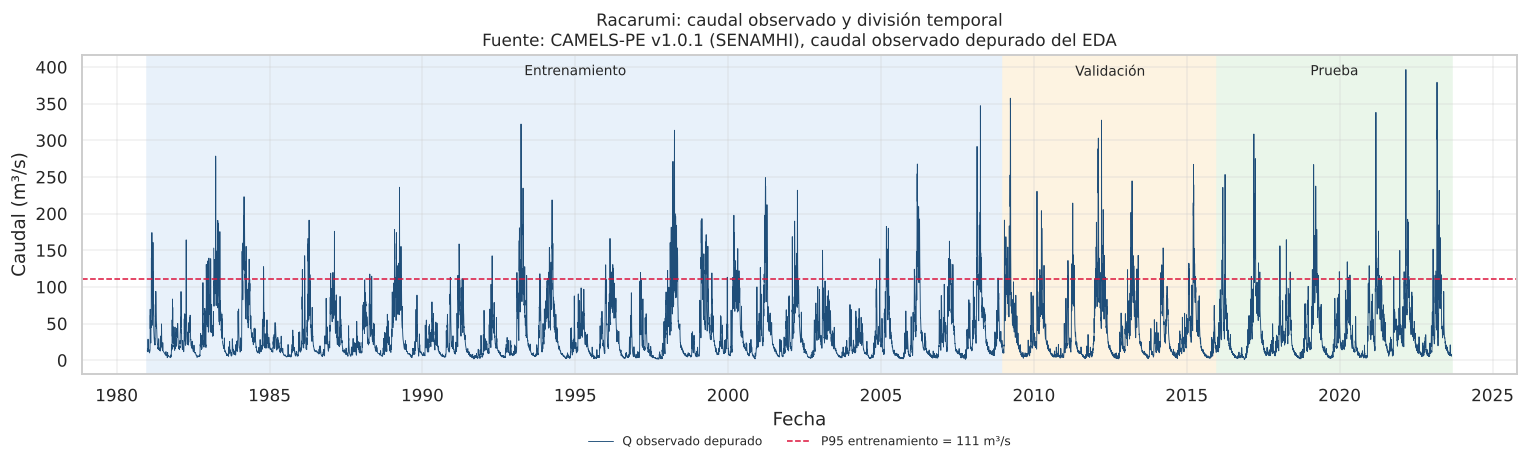

In [3]:
fig, ax = plt.subplots(figsize=(14, 4.4))
ax.plot(q.index, q, color='#1f4e79', lw=0.6, label='Q observado depurado')
lims = [(q.index.min(), pd.Timestamp(C.FIN_ENTRENAMIENTO), 'Entrenamiento', '#e8f1fa'),
        (pd.Timestamp(C.FIN_ENTRENAMIENTO), pd.Timestamp(C.FIN_VALIDACION), 'Validación', '#fdf3e1'),
        (pd.Timestamp(C.FIN_VALIDACION), q.index.max(), 'Prueba', '#eaf6ea')]
for a, b, et, col in lims:
    ax.axvspan(a, b, color=col, zorder=0)
    ax.text(a + (b - a) / 2, 0.97, et, transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=9)
ax.axhline(P95, color='crimson', ls='--', lw=1, label=f'P95 entrenamiento = {P95:,.0f} m³/s')
if len(esc):
    ax.plot(esc, q.reindex(esc), 'v', color='darkorange', ms=5, label=f'Escalones de nivel ({len(esc)})')
ax.set_ylabel('Caudal (m³/s)'); ax.set_xlabel('Fecha')
ax.set_title(f'{ESTACION}: caudal observado y división temporal\n{FUENTE}', fontsize=11)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), fontsize=8, ncol=3, frameon=False); ax.grid(True, alpha=0.3)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig01_serie_division.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:** el Chancay-Lambayeque en Racarumi (vertiente del Pacífico) es un río de respuesta rápida: caudal base de 5–20 m³/s en estiaje y picos de 150–400 m³/s que duran pocos días, casi siempre entre enero y abril. Los dos mayores picos del registro están en la prueba (397 m³/s en 2022 y 379 m³/s en 2023).

---
## 3. Métodos de referencia
Todo modelo se mide frente a dos referencias sin aprendizaje: la **persistencia** (Q(t + h) = Q(t)) y la **climatología** del día del año, en los 30 horizontes de la prueba. La climatología de la evaluación final usa entrenamiento + validación, los mismos años con que se reentrenan los modelos.

In [4]:
CLIM_E = C.climatologia(q, hasta=C.FIN_ENTRENAMIENTO)
CLIM_F = C.climatologia(q, hasta=C.FIN_VALIDACION)
idx_p = p['pru']
OBS = m.q_obs[idx_p]
PERS = C.pred_persistencia(m, idx_p)
CLIM = C.pred_climatologia(m, idx_p, CLIM_F)
ref = pd.DataFrame({'NSE persistencia': [C.nse(OBS[:, j], PERS[:, j]) for j in range(H)],
                    'NSE climatología': [C.nse(OBS[:, j], CLIM[:, j]) for j in range(H)],
                    'MAE persistencia': [C.mae(OBS[:, j], PERS[:, j]) for j in range(H)],
                    'MAE climatología': [C.mae(OBS[:, j], CLIM[:, j]) for j in range(H)]},
                   index=pd.Index(C.HORIZONTES, name='h'))
ref.to_csv(RUTA_TAB / 'tabla_referencias_prueba.csv')
cruce = ref.index[ref['NSE persistencia'] < ref['NSE climatología']]
print('La climatología supera a la persistencia (NSE) desde h =', int(cruce.min()) if len(cruce) else '> 30')
ref.loc[H_CLAVE].round(3)

La climatología supera a la persistencia (NSE) desde h = 5


,NSE persistencia,NSE climatología,MAE persistencia,MAE climatología
h,,,,
1,0.837,0.460,7.892,18.344
2,0.686,0.460,11.582,18.336
3,0.573,0.460,13.833,18.340
5,0.391,0.459,16.817,18.343
7,0.262,0.460,18.765,18.337
10,0.125,0.462,21.012,18.299
15,0.019,0.463,23.396,18.150
20,-0.038,0.480,24.511,17.670
30,-0.171,0.488,27.102,17.422


**Interpretación:**
- **La persistencia se degrada rápido:** NSE 0.837 a 1 día, 0.573 a 3 días, 0.262 a 7 días, 0.02 a 15 días y −0.17 a 30 días.
- **La climatología tiene NSE ≈ 0.46–0.49** y supera a la persistencia desde los **5 días**: desde esa semana, la época del año informa más que el caudal de hoy.

---
## 4. Ajuste de hiperparámetros (validación temporal)
Cada combinación de la malla de un modelo se entrena con el entrenamiento (hasta 2008) y pronostica toda la validación; la corrección de Duan se estima **solo con 2009–2011** y el criterio es el NSE medio de los 30 horizontes en **2012–2015** (m³/s).
- **XGBoost:** sin parada temprana. El número de árboles (100, 200 o 400) se evalúa por etapas con un solo ajuste: los primeros k árboles de un ajuste de 400 son idénticos a un ajuste de k árboles.
- **KNN:** además de k y la ponderación, elige cuántos días de historia usa la distancia (3, 7, 15 o 30), porque muchos rezagos redundantes pueden empeorar la búsqueda de análogos.
- **LSTM:** para cada combinación entrena hasta 2004 y detiene con 2005–2008; luego reentrena con todo el entrenamiento esas épocas y se compara en validación.
**Presupuesto de búsqueda:** entre 1 y 40 combinaciones por modelo (tabla siguiente); se registran configuraciones, segundos y semilla. Los presupuestos son distintos entre modelos: las diferencias pequeñas no se atribuyen solo al algoritmo.

In [5]:
X, nombres = C.matriz_tabular(m)
ie, iv = p['ent'], p['val']
OBS_V = VC.obs_sel                                        # observado del bloque de selección (2012–2015)
a_q_val = VC.a_q                                          # Duan de 2009–2011 aplicado a 2012–2015

filas, mejores = [], {}
for nombre in MODELOS:
    if nombre == 'LSTM':
        continue
    sub = C.ajustar_malla(nombre, X[ie], m.y[ie], X[iv], a_q_val, OBS_V)
    filas += sub
    mejor = max(sub, key=lambda f: f['NSE_val'])
    mejores[nombre] = json.loads(mejor['parametros'])
    print(f"{nombre:22s} {len(sub):3d} combinaciones | mejor NSE medio selección = {mejor['NSE_val']:.4f} con {mejores[nombre]}")

ie_in = ie[m.fechas[ie] + pd.Timedelta(days=H) <= pd.Timestamp(C.FIN_PARADA)]
ie_par = ie[m.fechas[ie] > pd.Timestamp(C.FIN_PARADA)]
for params in C.combinaciones(C.MALLAS['LSTM']):
    t0 = time.time()
    lp = C.LSTMProtocolo(m, ie_in, ie_par, **params).ajustar(ie)
    nv = C.nse_medio(a_q_val(lp.predecir(iv)), OBS_V)
    filas.append(dict(modelo='LSTM', parametros=json.dumps({**params, 'epocas': lp.epocas}), NSE_val=nv, segundos=time.time() - t0))
sub = [f for f in filas if f['modelo'] == 'LSTM']
mejor_lstm = json.loads(max(sub, key=lambda f: f['NSE_val'])['parametros'])
mejores['LSTM'] = {k: v for k, v in mejor_lstm.items() if k != 'epocas'}
print(f"{'LSTM':22s} {len(sub):3d} combinaciones | mejor NSE medio selección = {max(f['NSE_val'] for f in sub):.4f} con {mejor_lstm} "
      f"(parada: entrena {len(ie_in):,} muestras, detiene con {len(ie_par):,})")

ajuste = pd.DataFrame(filas)
ajuste['semilla'] = C.SEMILLA
ajuste = ajuste.rename(columns={'NSE_val': 'NSE_seleccion'})
ajuste.to_csv(RUTA_TAB / 'tabla_ajuste_hiperparametros.csv', index=False)
presupuesto = ajuste.groupby('modelo', sort=False).agg(combinaciones=('parametros', 'count'), segundos=('segundos', 'sum'),
                                                       NSE_sel_mejor=('NSE_seleccion', 'max'), NSE_sel_peor=('NSE_seleccion', 'min'))
presupuesto.to_csv(RUTA_TAB / 'tabla_presupuesto_busqueda.csv')
presupuesto.round(3)

Regresión lineal         1 combinaciones | mejor NSE medio selección = 0.5531 con {}


Random Forest            8 combinaciones | mejor NSE medio selección = 0.5362 con {'max_depth': 20, 'min_samples_leaf': 5, 'max_features': 1.0}


XGBoost                 24 combinaciones | mejor NSE medio selección = 0.5313 con {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 10.0, 'n_estimators': 200}


KNN                     40 combinaciones | mejor NSE medio selección = 0.5323 con {'n_neighbors': 40, 'weights': 'distance', 'ventana': 3}


MLP                      8 combinaciones | mejor NSE medio selección = 0.5365 con {'hidden_layer_sizes': [64], 'alpha': 0.01, 'max_iter': 200}


LSTM                     4 combinaciones | mejor NSE medio selección = 0.5611 con {'oculto': 64, 'dropout': 0.2, 'epocas': 5} (parada: entrena 7,878 muestras, detiene con 1,400)


,combinaciones,segundos,NSE_sel_mejor,NSE_sel_peor
modelo,,,,
Regresión lineal,1,0.033,0.553,0.553
Random Forest,8,174.150,0.536,0.494
XGBoost,24,271.625,0.531,0.483
KNN,40,3.129,0.532,0.349
MLP,8,29.222,0.536,0.341
LSTM,4,37.762,0.561,0.546


**Interpretación:**
- **NSE medio en el bloque de selección (2012–2015)**, con la corrección de retransformación estimada en 2009–2011: LSTM 0.561, regresión lineal 0.553, MLP 0.536, Random Forest 0.536, KNN 0.532 y XGBoost 0.531 (mejor configuración de cada uno, semilla 42).
- **Configuraciones elegidas:** la LSTM con 64 unidades, dropout 0.2 y 5 épocas (detenida con 2005–2008); la MLP con una capa de 64 y 200 épocas; Random Forest con profundidad 20; XGBoost con profundidad 3 y 200 árboles; KNN con 40 vecinos ponderados y **solo 3 días** de historia.
- **Presupuesto de búsqueda:** de 1 a 40 combinaciones por modelo (unos 5 minutos en total). Los presupuestos difieren entre modelos, así que las diferencias pequeñas no se atribuyen solo al algoritmo.

---
## 5. Modelos finales y evaluación en prueba
Pasos de la evaluación final:
1. Con los mejores hiperparámetros, cada modelo se entrena con el entrenamiento y pronostica la validación. En el bloque de selección (2012–2015) el pronóstico usa el factor de Duan de 2009–2011: con él se aplica la **regla de selección** (sección 5.2) y se arma el combinado. Con los residuos de **toda** la validación se estima el factor que se usa en la prueba.
2. Se reentrena con entrenamiento + validación y se evalúa **una sola vez** en prueba. Los modelos estocásticos se repiten con 3 semillas y se promedian.
3. **Combinado por horizonte:** para cada h, el modelo con mejor NSE en ese h en el bloque de selección (no compite en la selección porque su NSE de selección es optimista por construcción).
4. Se guarda también la **mediana pronosticada** (sin factor de Duan) de validación y prueba: es la que usan los avisos (cuaderno 04), que así no dependen de ningún factor estimado.
5. Se registra cuántos pronósticos negativos (posibles por −ε) se recortan a 0.

In [6]:
it = np.concatenate([ie, iv])
PRED, PRED_V, PRED_MED, PRED_MED_V, FACTOR, NSE_VAL, SEM, NEG = {}, {}, {}, {}, {}, {}, {}, {}
for nombre in MODELOS:
    t0 = time.time()
    semillas = C.SEMILLAS if nombre in C.ESTOCASTICOS else [C.SEMILLA]
    yv_s, yp_s = [], []
    for s in semillas:
        if nombre == 'LSTM':
            lp = C.LSTMProtocolo(m, ie_in, ie_par, semilla=s, **mejores['LSTM']).ajustar(ie)
            yv_s.append(lp.predecir(iv))
            yp_s.append(lp.reajustar(it).predecir(idx_p))
        else:
            yv_s.append(C.crear_tabular(nombre, mejores[nombre], s).fit(X[ie], m.y[ie]).predict(X[iv]))
            mod = C.crear_tabular(nombre, mejores[nombre], s).fit(X[it], m.y[it])
            yp_s.append(mod.predict(X[idx_p]))
            if nombre == C.BASE_AUX and s == C.SEMILLA:
                MODELO_AUX = mod                                  # modelo de los análisis auxiliares (secciones 9, 10)
    yv, yp = np.mean(yv_s, 0), np.mean(yp_s, 0)
    FACTOR[nombre] = C.factor_duan(m.y[iv], yv)                 # toda la validación → se aplica en prueba
    PRED_V[nombre] = VC.a_q(yv)                                  # bloque de selección con el factor de 2009–2011
    PRED_MED_V[nombre] = C.a_caudal(m, yv, iv)                   # mediana, toda la validación (avisos)
    PRED_MED[nombre] = C.a_caudal(m, yp, idx_p)                  # mediana, prueba (avisos)
    PRED[nombre], np_neg = C.a_caudal(m, yp, idx_p, FACTOR[nombre], contar=True)
    NEG[nombre] = dict(prueba=np_neg)
    NSE_VAL[nombre] = C.nse_medio(PRED_V[nombre], OBS_V)
    SEM[nombre] = [C.a_caudal(m, y, idx_p, FACTOR[nombre]) for y in yp_s] if len(semillas) > 1 else []
    print(f"{nombre:22s} {len(semillas)} semilla(s) | {time.time() - t0:6.1f} s | factor h=1/7/30: "
          f"{FACTOR[nombre][0]:.3f} / {FACTOR[nombre][6]:.3f} / {FACTOR[nombre][29]:.3f} | negativos recortados: {np_neg}")

SELEC, MEJOR, MAS_ALTO = C.seleccion_pareada(VC.fechas_sel, OBS_V, {n: PRED_V[n] for n in MODELOS}, B=B)
assert SELEC.loc[MEJOR, 'clase'] in ('mejor', 'equivalente')
nse_v_h = pd.DataFrame({n: [C.nse(OBS_V[:, j], PRED_V[n][:, j]) for j in range(H)] for n in MODELOS}, index=C.HORIZONTES)
ELEGIDO = nse_v_h.idxmax(axis=1)
for dic in (PRED, PRED_V, PRED_MED, PRED_MED_V):
    dic[COMB] = np.column_stack([dic[ELEGIDO[h]][:, h - 1] for h in C.HORIZONTES])
TODOS = MODELOS + [COMB]
pd.DataFrame(NEG).T.to_csv(RUTA_TAB / 'tabla_negativos_recortados.csv')
print('\nNSE medio en el bloque de selección:', {k: round(v, 4) for k, v in sorted(NSE_VAL.items(), key=lambda x: -x[1])})
print(f'Mayor NSE medio: {MAS_ALTO} | seleccionado por la regla (más simple entre equivalentes): {MEJOR}')
print('Combinado por horizonte (selección):', ELEGIDO.groupby(ELEGIDO).apply(lambda s: ', '.join(map(str, s.index))).to_dict())

Regresión lineal       1 semilla(s) |    0.1 s | factor h=1/7/30: 1.034 / 1.184 / 1.286 | negativos recortados: 0


Random Forest          3 semilla(s) |  230.3 s | factor h=1/7/30: 1.025 / 1.161 / 1.259 | negativos recortados: 0


XGBoost                3 semilla(s) |   33.0 s | factor h=1/7/30: 1.031 / 1.167 / 1.243 | negativos recortados: 0
KNN                    1 semilla(s) |    0.2 s | factor h=1/7/30: 1.030 / 1.170 / 1.269 | negativos recortados: 0


MLP                    3 semilla(s) |   22.6 s | factor h=1/7/30: 1.031 / 1.170 / 1.246 | negativos recortados: 0


LSTM                   3 semilla(s) |   36.5 s | factor h=1/7/30: 1.033 / 1.162 / 1.210 | negativos recortados: 0



NSE medio en el bloque de selección: {'LSTM': 0.5599, 'Regresión lineal': 0.5531, 'MLP': 0.5458, 'Random Forest': 0.5365, 'KNN': 0.5323, 'XGBoost': 0.5321}
Mayor NSE medio: LSTM | seleccionado por la regla (más simple entre equivalentes): LSTM
Combinado por horizonte (selección): {'KNN': '21', 'LSTM': '3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 22, 23', 'MLP': '2', 'Regresión lineal': '24, 25, 26, 27, 28, 29, 30', 'XGBoost': '1'}


In [7]:
TAB = {n: C.tabla_metricas(OBS, PRED[n], PERS, CLIM) for n in TODOS}
largo = pd.concat({n: t for n, t in TAB.items()}, names=['modelo', 'h']).reset_index()
largo.to_csv(RUTA_TAB / 'tabla_metricas_prueba.csv', index=False)
vista = largo[largo['h'].isin([1, 3, 7, 15, 30])].pivot(index='modelo', columns='h', values='NSE').reindex(TODOS)
vista.loc['Persistencia'] = ref.loc[[1, 3, 7, 15, 30], 'NSE persistencia'].values
vista.loc['Climatología'] = ref.loc[[1, 3, 7, 15, 30], 'NSE climatología'].values
vista.columns = [f'NSE h={h}' for h in vista.columns]
vista.insert(0, 'NSE medio selección', pd.Series(NSE_VAL))
vista.round(3)

,NSE medio selección,NSE h=1,NSE h=3,NSE h=7,NSE h=15,NSE h=30
modelo,,,,,,
Regresión lineal,0.553,0.847,0.647,0.483,0.424,0.448
Random Forest,0.537,0.855,0.672,0.521,0.448,0.448
XGBoost,0.532,0.859,0.662,0.505,0.409,0.450
KNN,0.532,0.848,0.637,0.444,0.351,0.412
MLP,0.546,0.858,0.673,0.516,0.453,0.471
LSTM,0.560,0.851,0.666,0.508,0.455,0.468
Combinado por horizonte,NaN,0.859,0.666,0.508,0.455,0.448
Persistencia,NaN,0.837,0.573,0.262,0.019,-0.171
Climatología,NaN,0.460,0.460,0.460,0.463,0.488


In [8]:
largo[largo['h'].isin([1, 7, 30])].set_index(['h', 'modelo'])[['NSE', 'KGE', 'MAE', 'RMSE', 'PBIAS', 'hab_pers', 'hab_clim']].round(3)

,,NSE,KGE,MAE,RMSE,PBIAS,hab_pers,hab_clim
h,modelo,,,,,,,
1,Regresión lineal,0.847,0.916,7.809,16.679,0.573,0.060,0.717
7,Regresión lineal,0.483,0.643,17.062,30.693,1.532,0.300,0.042
30,Regresión lineal,0.448,0.500,18.323,30.155,-2.822,0.529,-0.079
1,Random Forest,0.855,0.899,7.584,16.261,-0.586,0.106,0.731
7,Random Forest,0.521,0.654,16.440,29.528,-0.339,0.352,0.113
30,Random Forest,0.448,0.554,18.276,30.154,-0.959,0.529,-0.078
1,XGBoost,0.859,0.908,7.578,16.034,0.263,0.131,0.738
7,XGBoost,0.505,0.661,16.718,30.043,1.633,0.329,0.082
30,XGBoost,0.450,0.558,18.110,30.117,-1.639,0.530,-0.076


**Interpretación:**
- **A 1 día** los seis modelos tienen NSE 0.847–0.859 (persistencia 0.837): una mejora real pero pequeña.
- **A 7 días** el NSE es 0.444–0.521, cerca de la climatología (0.460); KNN queda por debajo de ella.
- **A 30 días** el NSE es 0.412–0.471 y **ningún modelo supera a la climatología** (0.488).
- **El combinado por horizonte** (XGBoost a 1 día, MLP a 2, LSTM de 3 a 23 y regresión lineal de 24 a 30, elegidos en el bloque de selección) no mejora a los mejores modelos individuales en prueba.
- **Sesgo total pequeño:** PBIAS a 7 días entre −0.3 % y +4.1 %.

**Figura 2.** Desempeño en prueba según el horizonte: (a) NSE de modelos y referencias; (b) habilidad frente a la persistencia; (c) habilidad frente a la climatología.

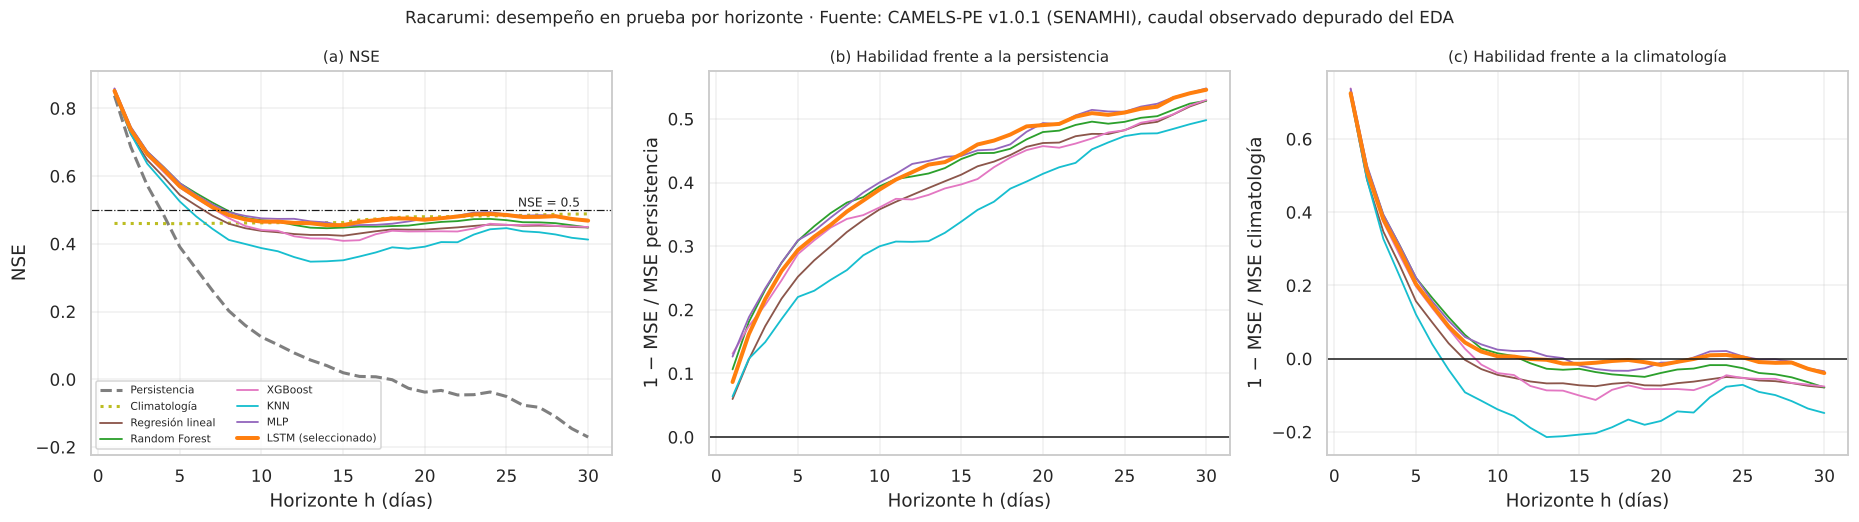

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
hh = np.array(C.HORIZONTES)
ax[0].plot(hh, ref['NSE persistencia'], '--', color=COLOR['Persistencia'], lw=2, label='Persistencia')
ax[0].plot(hh, ref['NSE climatología'], ':', color=COLOR['Climatología'], lw=2, label='Climatología')
for n in MODELOS:
    lw = 2.6 if n == MEJOR else 1.2
    ax[0].plot(hh, TAB[n]['NSE'], color=COLOR[n], lw=lw, label=n + (' (seleccionado)' if n == MEJOR else ''))
    ax[1].plot(hh, TAB[n]['hab_pers'], color=COLOR[n], lw=lw)
    ax[2].plot(hh, TAB[n]['hab_clim'], color=COLOR[n], lw=lw)
ax[0].axhline(0.5, color='k', lw=0.8, ls='-.'); ax[0].text(29.5, 0.51, 'NSE = 0.5', ha='right', fontsize=8)
for a, t in zip(ax, ['(a) NSE', '(b) Habilidad frente a la persistencia', '(c) Habilidad frente a la climatología']):
    a.set_title(t, fontsize=10); a.set_xlabel('Horizonte h (días)'); a.grid(True, alpha=0.3)
for a in ax[1:]:
    a.axhline(0, color='k', lw=1)
ax[0].set_ylabel('NSE'); ax[1].set_ylabel('1 − MSE / MSE persistencia'); ax[2].set_ylabel('1 − MSE / MSE climatología')
ax[0].legend(fontsize=7, loc='lower left', ncol=2)
fig.suptitle(f'{ESTACION}: desempeño en prueba por horizonte · {FUENTE}', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig02_desempeno_horizonte.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:**
- **(a)** Todos los modelos bajan de NSE ≈ 0.85 a ≈ 0.5 en la primera semana y luego quedan en la franja de la climatología (0.41–0.47); KNN es el más bajo entre 7 y 20 días.
- **(b)** La habilidad frente a la persistencia **crece** con el horizonte porque la persistencia empeora, no porque los modelos mejoren.
- **(c)** La habilidad frente a la climatología cae de ≈ 0.72 a 1 día a ≈ 0.1 a 7 días y a cero hacia los 9–12 días; después todos quedan en cero o algo por debajo.

### 5.1 Variabilidad entre semillas
En los modelos estocásticos, el pronóstico de cada semilla (con la misma corrección de retransformación) se evalúa por separado y se compara con el promedio que se reporta.

In [10]:
filas_s = []
for n, lista in SEM.items():
    for k, pr in enumerate(lista):
        t = C.tabla_metricas(OBS, pr, PERS, CLIM)
        filas_s.append({'modelo': n, 'semilla': C.SEMILLAS[k], 'H puntual (d)': C.horizonte_util(t),
                        **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}})
    t = TAB[n]
    filas_s.append({'modelo': n, 'semilla': 'promedio (reportado)', 'H puntual (d)': C.horizonte_util(t),
                    **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}})
semillas_tab = pd.DataFrame(filas_s)
semillas_tab.to_csv(RUTA_TAB / 'tabla_semillas.csv', index=False)
semillas_tab.set_index(['modelo', 'semilla']).round(3) if len(semillas_tab) else 'modo rápido: una sola semilla'

H puntual (d)  NSE h=1  NSE h=7  \
modelo           semilla                                                 
Regresión lineal promedio (reportado)              7    0.847    0.483   
Random Forest    42                               11    0.855    0.522   
                 43                               11    0.854    0.522   
                 44                               11    0.855    0.519   
                 promedio (reportado)             11    0.855    0.521   
XGBoost          42                                8    0.858    0.507   
                 43                                8    0.859    0.502   
                 44                                8    0.857    0.503   
                 promedio (reportado)              8    0.859    0.505   
KNN              promedio (reportado)              6    0.848    0.444   
MLP              42                                9    0.851    0.509   
                 43                                8    0.859    0.494   
                 44                               11    0.858    0.516   
                 promedio (reportado)             14    0.858    0.516   
LSTM             42                               13    0.852    0.517   
                 43                                9    0.851    0.504   
                 44                                8    0.850    0.494   
                 promedio (reportado)             11    0.851    0.508   

                                       NSE h=15  NSE h=30  
modelo           semilla                                   
Regresión lineal promedio (reportado)     0.424     0.448  
Random Forest    42                       0.449     0.448  
                 43                       0.448     0.447  
                 44                       0.445     0.447  
                 promedio (reportado)     0.448     0.448  
XGBoost          42                       0.405     0.449  
                 43                       0.410     0.448  
                 44                       0.409     0.448  
                 promedio (reportado)     0.409     0.450  
KNN              promedio (reportado)     0.351     0.412  
MLP              42                       0.440     0.467  
                 43                       0.433     0.439  
                 44                       0.436     0.453  
                 promedio (reportado)     0.453     0.471  
LSTM             42                       0.463     0.463  
                 43                       0.447     0.458  
                 44                       0.437     0.459  
                 promedio (reportado)     0.455     0.468

**Interpretación:**
- **Random Forest y XGBoost son estables entre semillas** (NSE con diferencias ≤ 0.005; H puntual igual en las tres).
- **Las redes varían más:** H puntual de 9, 8 y 11 días en la MLP y de 13, 9 y 8 en la LSTM; el NSE a 7 días va de 0.494 a 0.516 (MLP) y de 0.494 a 0.517 (LSTM).
- **El promedio de semillas es mejor que cada semilla** en las redes (MLP: H puntual 14 días con el promedio). Diferencias de 0.01–0.02 de NSE entre modelos están dentro de lo que cambia una red con otra semilla.

### 5.2 Regla de selección: comparación pareada en el bloque de selección
La regla fijada antes de evaluar (sección 0.3) se aplica a los seis modelos en 2012–2015: diferencia de NSE medio con el de mayor NSE, intervalo del 90 % por bootstrap pareado de meses (las mismas réplicas para todos) y clase (equivalente, peor o inconcluso, con margen ±0.01). El seleccionado es el más simple entre el mejor y sus equivalentes.
**Cómo leerlo:** "inconcluso" no es igualdad: la incertidumbre no permite decir ni que es peor ni que es equivalente.

In [11]:
SELEC.to_csv(RUTA_TAB / 'tabla_seleccion.csv')
print(f'Bloque de selección: {VC.resumen()["selección"]} ({len(OBS_V):,} emisiones) | margen ±{C.MARGEN_NSE} | B = {B}')
SELEC.round(4)

Bloque de selección: 2012-01-01 a 2015-12-01 (1,369 emisiones) | margen ±0.01 | B = 1000


,NSE medio selección,diferencia con el mejor,IC90 inferior,IC90 superior,clase,seleccionado
modelo,,,,,,
LSTM,0.5599,0.0000,NaN,NaN,mejor,True
Regresión lineal,0.5531,-0.0067,-0.0387,0.0251,inconcluso,False
MLP,0.5458,-0.0141,-0.0445,0.0148,inconcluso,False
Random Forest,0.5365,-0.0234,-0.0597,0.0098,inconcluso,False
KNN,0.5323,-0.0276,-0.0627,0.0005,inconcluso,False
XGBoost,0.5321,-0.0278,-0.0514,-0.0033,peor,False


**Interpretación — la regla selecciona la LSTM, pero su ventaja no está demostrada:**
- **La LSTM tiene el mayor NSE medio** (0.560 con el promedio de 3 semillas). Ningún otro modelo es **equivalente** según el margen fijado (IC 90 % dentro de ±0.01), así que la regla la selecciona.
- **La regresión lineal queda 0.007 por debajo con un IC 90 % de −0.039 a +0.025: inconcluso.** Lo mismo la MLP (−0.014), Random Forest (−0.023) y KNN (−0.028). Solo XGBoost es **peor** (−0.028; IC −0.051 a −0.003).
- **Cómo leerlo:** con cuatro años de selección la incertidumbre es demasiado amplia para decir que la LSTM es mejor o que la regresión lineal es igual. La regresión lineal sigue siendo una **alternativa práctica** (más simple y estable), sin afirmar que se demostró la igualdad.

### 5.3 Sensibilidad a la corrección de retransformación en prueba
La prueba se repite con el factor de Duan transferido (principal) y sin él (mediana pronosticada), para ver cuánto depende el resultado de un factor estimado con un modelo distinto del reentrenado.

In [12]:
filas_r = []
for n in MODELOS:
    tm = C.tabla_metricas(OBS, PRED_MED[n], PERS, CLIM)
    for et, t in [('con factor de Duan (principal)', TAB[n]), ('sin factor (mediana)', tm)]:
        filas_r.append({'modelo': n, 'retransformación': et, 'H puntual (d)': C.horizonte_util(t),
                        **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}, 'PBIAS h=7 (%)': t.loc[7, 'PBIAS']})
retrans = pd.DataFrame(filas_r)
retrans.to_csv(RUTA_TAB / 'tabla_sensibilidad_retransformacion.csv', index=False)
fac_tab = pd.DataFrame({n: FACTOR[n][[0, 6, 14, 29]] for n in MODELOS}, index=['factor h=1', 'h=7', 'h=15', 'h=30']).T
fac_tab.to_csv(RUTA_TAB / 'tabla_factores_duan.csv')
display(fac_tab.round(3))
retrans.set_index(['modelo', 'retransformación']).round(3)

,factor h=1,h=7,h=15,h=30
Regresión lineal,1.034,1.184,1.233,1.286
Random Forest,1.025,1.161,1.193,1.259
XGBoost,1.031,1.167,1.204,1.243
KNN,1.030,1.170,1.217,1.269
MLP,1.031,1.170,1.203,1.246
LSTM,1.033,1.162,1.191,1.210


H puntual (d)  NSE h=1  \
modelo           retransformación                                         
Regresión lineal con factor de Duan (principal)              7    0.847   
                 sin factor (mediana)                        7    0.848   
Random Forest    con factor de Duan (principal)             11    0.855   
                 sin factor (mediana)                        8    0.854   
XGBoost          con factor de Duan (principal)              8    0.859   
                 sin factor (mediana)                        8    0.858   
KNN              con factor de Duan (principal)              6    0.848   
                 sin factor (mediana)                        7    0.850   
MLP              con factor de Duan (principal)             14    0.858   
                 sin factor (mediana)                        9    0.856   
LSTM             con factor de Duan (principal)             11    0.851   
                 sin factor (mediana)                        8    0.852   

                                                 NSE h=7  NSE h=15  NSE h=30  \
modelo           retransformación                                              
Regresión lineal con factor de Duan (principal)    0.483     0.424     0.448   
                 sin factor (mediana)              0.474     0.381     0.360   
Random Forest    con factor de Duan (principal)    0.521     0.448     0.448   
                 sin factor (mediana)              0.505     0.418     0.393   
XGBoost          con factor de Duan (principal)    0.505     0.409     0.450   
                 sin factor (mediana)              0.499     0.395     0.399   
KNN              con factor de Duan (principal)    0.444     0.351     0.412   
                 sin factor (mediana)              0.464     0.368     0.389   
MLP              con factor de Duan (principal)    0.516     0.453     0.471   
                 sin factor (mediana)              0.499     0.422     0.423   
LSTM             con factor de Duan (principal)    0.508     0.455     0.468   
                 sin factor (mediana)              0.502     0.429     0.410   

                                                 PBIAS h=7 (%)  
modelo           retransformación                               
Regresión lineal con factor de Duan (principal)          1.532  
                 sin factor (mediana)                  -14.378  
Random Forest    con factor de Duan (principal)         -0.339  
                 sin factor (mediana)                  -14.278  
XGBoost          con factor de Duan (principal)          1.633  
                 sin factor (mediana)                  -13.000  
KNN              con factor de Duan (principal)          4.091  
                 sin factor (mediana)                  -11.159  
MLP              con factor de Duan (principal)         -0.179  
                 sin factor (mediana)                  -14.834  
LSTM             con factor de Duan (principal)          0.842  
                 sin factor (mediana)                  -13.356

**Interpretación:**
- **El factor de Duan es grande en Racarumi:** 1.03 a 1 día, 1.16–1.18 a 7 días y 1.21–1.29 a 30 días (la distribución del error en log es asimétrica).
- **Sin él, la prueba empeora:** NSE a 30 días 0.02–0.09 menor, PBIAS a 7 días de −11 % a −15 % y H puntual de la LSTM de 11 a 8 días. El factor transferido al modelo reentrenado corrige casi todo el sesgo (PBIAS a 7 días entre −0.3 % y +4.1 %): la transferencia funciona, aunque su calibración no se presume perfecta.

---
## 6. Horizonte útil (indicador I4) e incertidumbre
La incertidumbre de H se estima remuestreando **meses completos** de emisión (1 000 réplicas), con las mismas réplicas para los 30 horizontes: en cada réplica se recalcula H con la definición principal y se resume su distribución. Para el mejor modelo se repite con bloques de 15 días y de 3 meses.
**Por qué:** días consecutivos están autocorrelacionados y los objetivos de emisiones vecinas se solapan; remuestrear bloques respeta parte de esa dependencia, y la sensibilidad al tamaño del bloque muestra cuánto depende de esa elección.

In [13]:
fechas_p = m.fechas[idx_p]
CURVAS, filas_hu, IC = {}, [], {}
for n in TODOS:
    cur = C.bootstrap_curvas(fechas_p, OBS, PRED[n], PERS, CLIM, B=B)
    CURVAS[n] = cur
    hz = C.horizontes(TAB[n], cur)
    IC[n] = pd.DataFrame({'pers_inf': np.percentile(cur['hab_pers'], 2.5, 0), 'pers_sup': np.percentile(cur['hab_pers'], 97.5, 0),
                          'clim_inf': np.percentile(cur['hab_clim'], 2.5, 0), 'clim_sup': np.percentile(cur['hab_clim'], 97.5, 0)},
                         index=pd.Index(C.HORIZONTES, name='h'))
    IC[n].to_csv(RUTA_TAB / f"ic_habilidad_{C.SLUG[n]}.csv")
    filas_hu.append({'modelo': n, **C.fila_h(hz), 'NSE medio selección': NSE_VAL.get(n, np.nan),
                     'NSE h=1': TAB[n].loc[1, 'NSE'], 'NSE h=7': TAB[n].loc[7, 'NSE'], 'NSE h=30': TAB[n].loc[30, 'NSE']})
hu_tab = pd.DataFrame(filas_hu).set_index('modelo')
hu_tab.to_csv(RUTA_TAB / 'tabla_horizonte_util.csv')
hu_tab.round(3)

,H puntual (d),H cota 95 % (d),H p05 (d),H mediana (d),H p95 (d),P(H ≥ 30),H marginal estricto (d),NSE ≥ 0.5 hasta (d),NSE medio selección,NSE h=1,NSE h=7,NSE h=30
modelo,,,,,,,,,,,,
Regresión lineal,7,5,5,8,22,0.020,4,6,0.553,0.847,0.483,0.448
Random Forest,11,6,6,11,29,0.037,6,7,0.537,0.855,0.521,0.448
XGBoost,8,5,5,8,19,0.018,5,7,0.532,0.859,0.505,0.450
KNN,6,4,4,6,12,0.000,4,5,0.532,0.848,0.444,0.412
MLP,14,6,6,13,30,0.068,6,7,0.546,0.858,0.516,0.471
LSTM,11,6,6,11,30,0.108,5,7,0.560,0.851,0.508,0.468
Combinado por horizonte,11,6,6,11,20,0.007,5,7,NaN,0.859,0.508,0.448


In [14]:
filas_b = []
for nombre_b, dias_b in [('15 días', 15), ('1 mes (principal)', None), ('3 meses', 91)]:
    hz = C.horizontes(TAB[MEJOR], C.bootstrap_curvas(fechas_p, OBS, PRED[MEJOR], PERS, CLIM, B=B, dias_bloque=dias_b))
    filas_b.append({'bloque': nombre_b, 'H cota 95 % (d)': hz['H_cota'], 'H p05 (d)': hz['H_p05'], 'H mediana (d)': hz['H_mediana'],
                    'H p95 (d)': hz['H_p95'], 'P(H ≥ 30)': hz['P_H30']})
bloques = pd.DataFrame(filas_b).set_index('bloque')
bloques.to_csv(RUTA_TAB / 'tabla_sensibilidad_bloque.csv')
print('Modelo seleccionado:', MEJOR)
bloques

Modelo seleccionado: LSTM


,H cota 95 % (d),H p05 (d),H mediana (d),H p95 (d),P(H ≥ 30)
bloque,,,,,
15 días,6,6,10,30,0.087
1 mes (principal),6,6,11,30,0.108
3 meses,5,5,10,30,0.145


**Interpretación — el pronóstico útil de Racarumi es de alrededor de una semana:**
- **H cota 95 %: 6 días** con la LSTM (modelo seleccionado); **4–6 días** según el modelo (KNN 4; regresión lineal y XGBoost 5; Random Forest, MLP y LSTM 6).
- **H puntual:** 11 días con la LSTM y 6–14 días según el modelo. El percentil 95 llega a 30 días y el 11 % de las réplicas tiene H ≥ 30: después de la primera semana la ventaja sobre la climatología es pequeña y depende de qué meses entren en la muestra.
- **Calidad (NSE ≥ 0.5):** hasta 5–7 días.
- **Longitud del bloque:** H cota de 6, 6 y 5 días con bloques de 15 días, 1 mes y 3 meses.

**Figura 3.** (a) Habilidad del mejor modelo frente a cada referencia con su IC 95 % **marginal** por horizonte (no es una banda simultánea); (b) distribución de H en las réplicas del bootstrap conjunto.

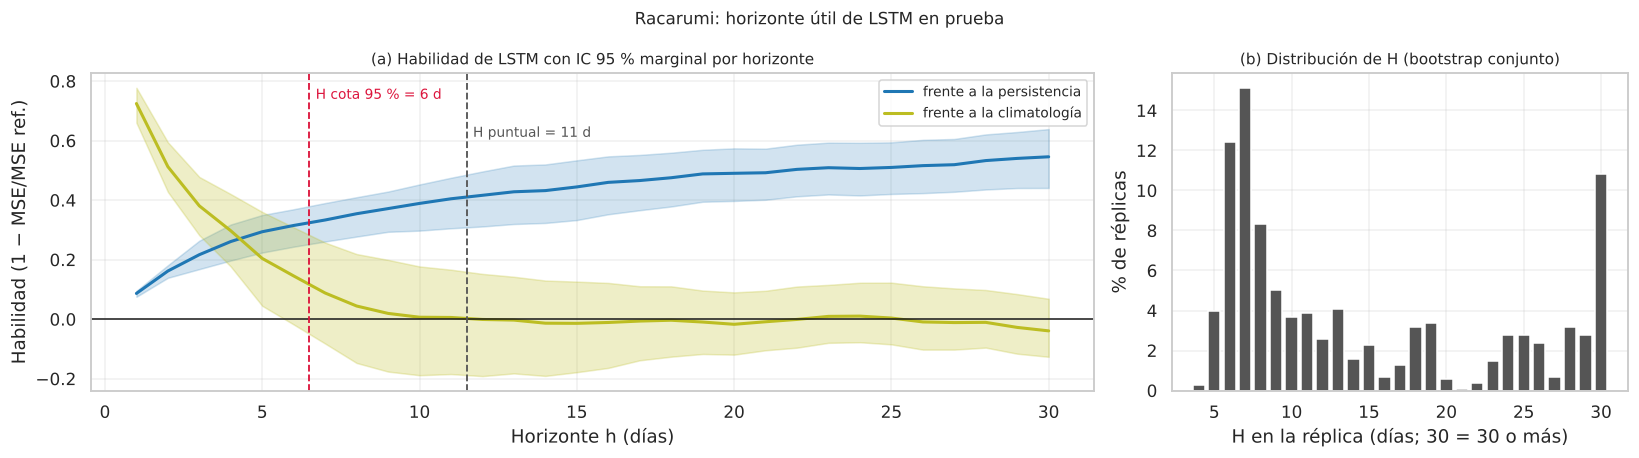

In [15]:
ic, cur = IC[MEJOR], CURVAS[MEJOR]
rep = C.replicas_h(cur)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [2.2, 1]})
ax[0].plot(hh, TAB[MEJOR]['hab_pers'], color='#1f77b4', lw=2, label='frente a la persistencia')
ax[0].fill_between(hh, ic['pers_inf'], ic['pers_sup'], color='#1f77b4', alpha=0.2)
ax[0].plot(hh, TAB[MEJOR]['hab_clim'], color='#bcbd22', lw=2, label='frente a la climatología')
ax[0].fill_between(hh, ic['clim_inf'], ic['clim_sup'], color='#bcbd22', alpha=0.25)
ax[0].axhline(0, color='k', lw=1)
hc, hp = int(hu_tab.loc[MEJOR, 'H cota 95 % (d)']), int(hu_tab.loc[MEJOR, 'H puntual (d)'])
for v, col, et, y in [(hc, 'crimson', f'H cota 95 % = {hc} d', 0.92), (hp, '#555', f'H puntual = {hp} d', 0.80)]:
    if 0 < v < 30:
        ax[0].axvline(v + 0.5, color=col, ls='--', lw=1.2)
        ax[0].text(v + 0.7, y, et, color=col, fontsize=9, transform=ax[0].get_xaxis_transform())
ax[0].set_xlabel('Horizonte h (días)'); ax[0].set_ylabel('Habilidad (1 − MSE/MSE ref.)'); ax[0].legend(fontsize=9); ax[0].grid(True, alpha=0.3)
ax[0].set_title(f'(a) Habilidad de {MEJOR} con IC 95 % marginal por horizonte', fontsize=10)
vals, cnt = np.unique(rep, return_counts=True)
ax[1].bar(vals, cnt / len(rep) * 100, color='#555', width=0.8)
ax[1].set_xlabel('H en la réplica (días; 30 = 30 o más)'); ax[1].set_ylabel('% de réplicas'); ax[1].grid(True, alpha=0.3)
ax[1].set_title('(b) Distribución de H (bootstrap conjunto)', fontsize=10)
fig.suptitle(f'{ESTACION}: horizonte útil de {MEJOR} en prueba', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig03_habilidad_ic.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:** **(a)** la habilidad de la LSTM frente a la persistencia (azul) es positiva con IC estrecho en los 30 días; el límite lo pone la climatología (verde), cuyo IC marginal incluye el cero desde los 6 días y cuya estimación queda en cero desde los 12. **(b)** La distribución de H tiene su mayor peso entre 6 y 12 días y una cola hasta 30: por eso la conclusión se expresa con la cota de 6 días y no con el valor puntual.

---
## 7. Evaluación en las fechas comunes de las dos estaciones
Métricas, horizonte útil y caudales altos se recalculan sobre la **intersección explícita** de las fechas de emisión válidas de prueba de Racarumi y Tamshiyacu (cada emisión con sus 30 objetivos observados, así que también coinciden los pares emisión–horizonte).
**Por qué:** un mismo límite de fecha no garantiza las mismas emisiones: los vacíos de cada estación son distintos. Esta es la base de la comparación entre estaciones (cuaderno 03). No se exige que ambos ríos tengan crecidas en las mismas fechas: se informa cuántos días altos tiene cada uno.

In [16]:
FC = C.fechas_comunes()
sel_c = np.where(fechas_p.isin(FC))[0]
assert len(sel_c) == len(FC), 'todas las fechas comunes deben ser emisiones válidas de esta estación'
print(f'Fechas comunes: {len(sel_c):,} de {len(fechas_p):,} emisiones de prueba de {ESTACION} '
      f'({FC.min():%Y-%m-%d} a {FC.max():%Y-%m-%d})')
TAB_C, filas_c, CURVAS_C = {}, [], {}
OBS_C, PERS_C, CLIM_C = OBS[sel_c], PERS[sel_c], CLIM[sel_c]
for n in TODOS:
    TAB_C[n] = C.tabla_metricas(OBS_C, PRED[n][sel_c], PERS_C, CLIM_C)
    CURVAS_C[n] = C.bootstrap_curvas(fechas_p[sel_c], OBS_C, PRED[n][sel_c], PERS_C, CLIM_C, B=B)
    filas_c.append({'modelo': n, **C.fila_h(C.horizontes(TAB_C[n], CURVAS_C[n])),
                    **{f'NSE h={h}': TAB_C[n].loc[h, 'NSE'] for h in (1, 3, 7, 15, 30)}})
pd.concat(TAB_C, names=['modelo', 'h']).reset_index().to_csv(RUTA_TAB / 'tabla_metricas_prueba_comun.csv', index=False)
ref_c = pd.DataFrame({'NSE persistencia': [C.nse(OBS_C[:, j], PERS_C[:, j]) for j in range(H)],
                      'NSE climatología': [C.nse(OBS_C[:, j], CLIM_C[:, j]) for j in range(H)]}, index=pd.Index(C.HORIZONTES, name='h'))
ref_c.to_csv(RUTA_TAB / 'tabla_referencias_prueba_comun.csv')
hu_c = pd.DataFrame(filas_c).set_index('modelo')
hu_c.to_csv(RUTA_TAB / 'tabla_horizonte_util_comun.csv')
CREC_C = {n: C.metricas_crecida(OBS_C, PRED[n][sel_c], P95) for n in TODOS}
CREC_C['Persistencia'] = C.metricas_crecida(OBS_C, PERS_C, P95)
pd.concat(CREC_C, names=['modelo', 'h']).reset_index().to_csv(RUTA_TAB / 'tabla_crecidas_prueba_comun.csv', index=False)
print(f"Días altos (Q(t+1) > P95) en fechas comunes: {int(CREC_C['Persistencia'].loc[1, 'n_altos'])}")
hu_c.round(3)

Fechas comunes: 2,373 de 2,521 emisiones de prueba de Racarumi (2016-01-01 a 2023-03-31)


Días altos (Q(t+1) > P95) en fechas comunes: 131


,H puntual (d),H cota 95 % (d),H p05 (d),H mediana (d),H p95 (d),P(H ≥ 30),H marginal estricto (d),NSE ≥ 0.5 hasta (d),NSE h=1,NSE h=3,NSE h=7,NSE h=15,NSE h=30
modelo,,,,,,,,,,,,,
Regresión lineal,8,5,5,7,19,0.017,4,6,0.846,0.642,0.479,0.418,0.445
Random Forest,11,6,6,10,28,0.030,6,7,0.854,0.666,0.517,0.445,0.445
XGBoost,8,6,6,8,19,0.012,5,7,0.858,0.656,0.503,0.407,0.448
KNN,6,4,4,6,13,0.001,4,5,0.846,0.629,0.443,0.352,0.417
MLP,14,6,6,12,30,0.071,6,7,0.857,0.665,0.512,0.451,0.468
LSTM,11,6,6,9,30,0.112,5,7,0.850,0.659,0.503,0.452,0.466
Combinado por horizonte,11,6,6,9,20,0.010,5,7,0.858,0.659,0.503,0.452,0.445


**Interpretación:** en las 2 373 fechas comunes (94 % de la prueba de Racarumi; se pierden emisiones de 2023 en que Tamshiyacu no tiene datos) el resultado se mantiene: **H cota 95 % de 6 días** con la LSTM y de 4–6 días con los demás modelos; 131 días altos.

---
## 8. Desempeño durante caudales elevados
Los días de prueba en que el caudal observado en t + h supera el P95 de entrenamiento se comparan con los ordinarios, por horizonte: error absoluto (MAE, RMSE en m³/s), error relativo mediano, sesgo (PBIAS) en días altos frente a ordinarios, y una tabla de contingencia **diaria** de días sobre el P95 (POD, FAR y CSI con las mismas unidades: días).
**Por qué:** un error porcentual pequeño en un río grande puede ser un error absoluto grande. La detección diaria **no distingue** entre anticipar un evento nuevo y pronosticar que uno ya iniciado continuará; eso se evalúa en el cuaderno 04.

In [17]:
CREC = {n: C.metricas_crecida(OBS, PRED[n], P95) for n in TODOS}
CREC['Persistencia'] = C.metricas_crecida(OBS, PERS, P95)
crec = pd.concat(CREC, names=['modelo', 'h']).reset_index()
crec.to_csv(RUTA_TAB / 'tabla_crecidas_prueba.csv', index=False)
print(f"Días de prueba con Q(t+1) > P95: {int(CREC['Persistencia'].loc[1, 'n_altos'])} de {len(OBS)}")
crec[crec['h'].isin([1, 3, 7, 15]) & crec['modelo'].isin([MEJOR, 'Persistencia'])].set_index(['modelo', 'h'])[
    ['n_altos', 'MAE_altos', 'MAE_ordinarios', 'error_rel_altos', 'error_rel_ordinarios', 'PBIAS_altos', 'POD', 'FAR', 'CSI']].round(3)

Días de prueba con Q(t+1) > P95: 148 de 2521


n_altos  MAE_altos  MAE_ordinarios  error_rel_altos  \
modelo       h                                                         
LSTM         1       148     41.814           5.639           22.502   
             3       148     57.313          10.195           32.504   
             7       149     67.714          13.314           35.023   
             15      146     75.820          14.581           43.031   
Persistencia 1       148     44.285           5.622           25.554   
             3       148     63.586          10.730           37.047   
             7       149     77.065          15.103           39.855   
             15      146     86.945          19.489           52.199   

                 error_rel_ordinarios  PBIAS_altos    POD    FAR    CSI  
modelo       h                                                           
LSTM         1                 13.984      -11.066  0.696  0.285  0.545  
             3                 26.122      -26.720  0.554  0.423  0.394  
             7                 34.807      -38.780  0.376  0.588  0.245  
             15                40.442      -46.832  0.199  0.721  0.131  
Persistencia 1                 12.529       -8.127  0.682  0.322  0.515  
             3                 22.340      -22.176  0.500  0.503  0.332  
             7                 31.431      -37.132  0.315  0.685  0.187  
             15                46.205      -50.222  0.171  0.832  0.093

**Interpretación (LSTM frente a persistencia, 148 días altos):**
- **Los días altos se pronostican peor que los ordinarios:** error relativo mediano de 22 % frente a 14 % a 1 día y de 35 % frente a 35 % a 7 días; en m³/s el error es mucho mayor (MAE de 42 frente a 6 m³/s a 1 día y de 68 frente a 13 m³/s a 7 días).
- **Subestimación sistemática que crece con el horizonte:** PBIAS en días altos de −11 % a 1 día, −27 % a 3 días, −39 % a 7 días y −47 % a 15 días.
- **Mejora pequeña sobre la persistencia** en días altos: MAE 42 frente a 44 m³/s a 1 día y 68 frente a 77 m³/s a 7 días.
- **Detección diaria del P95:** CSI 0.54 a 1 día (persistencia 0.52), 0.39 a 3 días (0.33) y 0.24 a 7 días (0.19). Incluye días dentro de eventos ya iniciados; no mide anticipación de cruces nuevos.

### 8.1 Errores por evento
Cada evento de la prueba (descripción retrospectiva: días sobre el P95; tramos separados por menos de 7 días observados bajo el umbral se unen) se describe con el mejor modelo y h = 1, 3 y 7:
- **error firmado en el pico** = pronóstico para el día del pico − pico observado (negativo = subestimación);
- **máximo pronosticado** con esa anticipación en la ventana del evento extendida h + 3 días después de su fin (para no truncar retrasos de hasta h días) y su **desfase** respecto al día del pico (positivo = tarde).
Se informa la distribución de los desfases, no solo su mediana.

In [18]:
EV = C.eventos(q, P95, '2016-01-01')
pos_p = {f: i for i, f in enumerate(fechas_p)}
filas_e = []
for r in EV.itertuples():
    for h in (1, 3, 7):
        i = pos_p.get(r.fecha_pico - pd.Timedelta(days=h))
        pron_pico = PRED[MEJOR][i, h - 1] if i is not None else np.nan
        dias_ev = pd.date_range(r.inicio - pd.Timedelta(days=3), r.fin + pd.Timedelta(days=h + 3))
        vals = [(d, PRED[MEJOR][pos_p[d - pd.Timedelta(days=h)], h - 1]) for d in dias_ev if (d - pd.Timedelta(days=h)) in pos_p]
        dmax, vmax = max(vals, key=lambda x: x[1]) if vals else (pd.NaT, np.nan)
        filas_e.append({'inicio': r.inicio.date(), 'pico obs (m³/s)': r.pico, 'h': h, 'pronóstico para el pico': pron_pico,
                        'error firmado en el pico (m³/s)': pron_pico - r.pico,
                        'error relativo firmado en el pico (%)': 100 * (pron_pico - r.pico) / r.pico,
                        'máximo pronosticado': vmax, 'error relativo firmado del máximo (%)': 100 * (vmax - r.pico) / r.pico,
                        'desfase del máximo (d)': (dmax - r.fecha_pico).days if vals else np.nan})
ev_tab = pd.DataFrame(filas_e)
ev_tab.to_csv(RUTA_TAB / 'tabla_eventos_pronostico.csv', index=False)
print(f'Eventos en prueba: {len(EV)} | modelo: {MEJOR}')
g = ev_tab.groupby('h')
res_ev = pd.DataFrame({
    'eventos con pronóstico': g['pronóstico para el pico'].count(),
    'error firmado mediano (m³/s)': g['error firmado en el pico (m³/s)'].median(),
    'error relativo firmado mediano (%)': g['error relativo firmado en el pico (%)'].median(),
    'eventos subestimados en el pico': g['error firmado en el pico (m³/s)'].apply(lambda s: int((s < 0).sum())),
    'error relativo mediano del máximo (%)': g['error relativo firmado del máximo (%)'].median(),
    'desfase p25 (d)': g['desfase del máximo (d)'].quantile(0.25), 'desfase mediano (d)': g['desfase del máximo (d)'].median(),
    'desfase p75 (d)': g['desfase del máximo (d)'].quantile(0.75),
    'eventos con desfase = h': pd.Series({h: int((ev_tab.loc[ev_tab['h'] == h, 'desfase del máximo (d)'] == h).sum()) for h in (1, 3, 7)})})
res_ev.to_csv(RUTA_TAB / 'tabla_eventos_resumen.csv')
res_ev.round(2)

Eventos en prueba: 34 | modelo: LSTM


,eventos con pronóstico,error firmado mediano (m³/s),error relativo firmado mediano (%),eventos subestimados en el pico,error relativo mediano del máximo (%),desfase p25 (d),desfase mediano (d),desfase p75 (d),eventos con desfase = h
1,32,-62.73,-42.91,32,-6.23,1.0,1.0,1.0,33
3,32,-78.74,-54.27,32,-18.98,3.0,3.0,3.0,33
7,33,-84.71,-52.58,33,-32.27,7.0,7.0,7.0,27


**Interpretación — 34 eventos en la prueba (32–33 con pronóstico para el día del pico):**
- **Error firmado en el día del pico (LSTM):** mediana de −63 m³/s (−43 %) a 1 día, −79 m³/s (−54 %) a 3 días y −85 m³/s (−53 %) a 7 días. **Todos los eventos** con pronóstico quedan subestimados en el día del pico.
- **Máximo pronosticado:** queda a −6 % del pico a 1 día, −19 % a 3 días y −32 % a 7 días, pero llega tarde.
- **Desfase:** a 1 día, los 33 eventos llegan 1 día tarde; a 3 días, los 33 llegan 3 días tarde; a 7 días, 27 de 34 llegan 7 días tarde (rango −5 a +8). El patrón dominante es reproducir el pico **h días después** de observarlo.

**Figura 4.** (a) Error relativo mediano en días altos y ordinarios; (b) error absoluto medio (MAE); (c) CSI diario de días sobre el P95; del mejor modelo y de la persistencia.

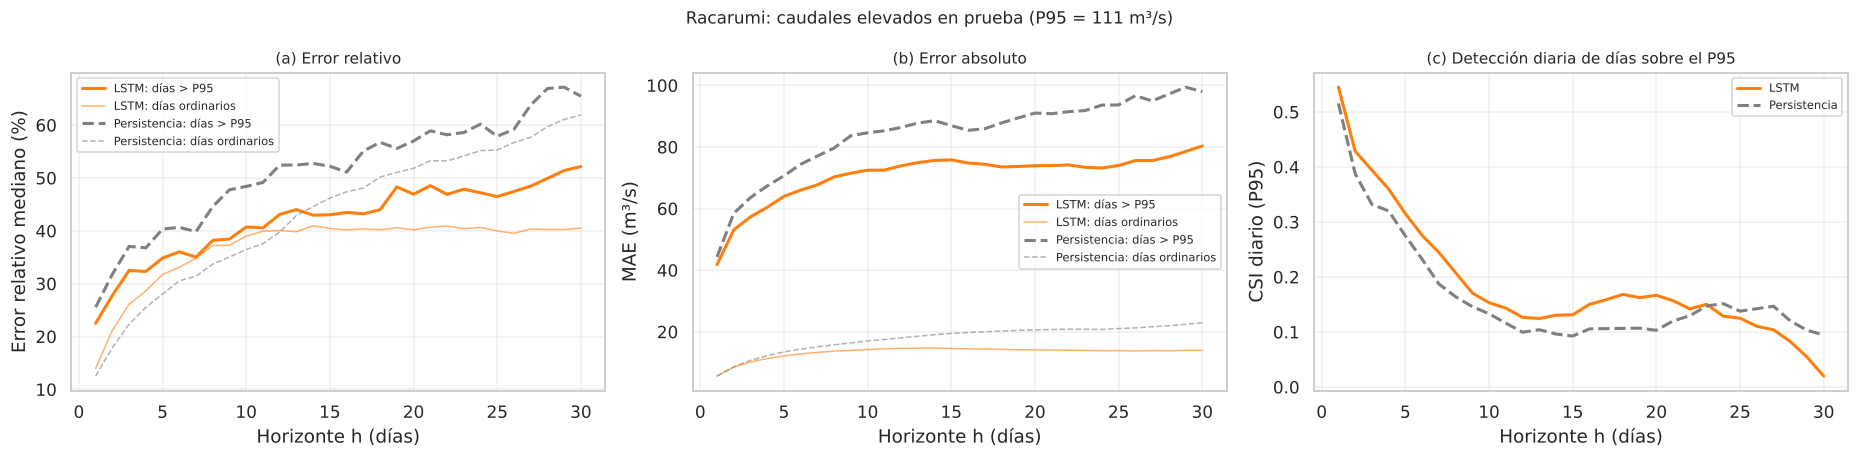

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for n, col, ls in [(MEJOR, COLOR[MEJOR], '-'), ('Persistencia', COLOR['Persistencia'], '--')]:
    t = CREC[n]
    ax[0].plot(hh, t['error_rel_altos'], color=col, ls=ls, lw=2, label=f'{n}: días > P95')
    ax[0].plot(hh, t['error_rel_ordinarios'], color=col, ls=ls, lw=1, alpha=0.6, label=f'{n}: días ordinarios')
    ax[1].plot(hh, t['MAE_altos'], color=col, ls=ls, lw=2, label=f'{n}: días > P95')
    ax[1].plot(hh, t['MAE_ordinarios'], color=col, ls=ls, lw=1, alpha=0.6, label=f'{n}: días ordinarios')
    ax[2].plot(hh, t['CSI'], color=col, ls=ls, lw=2, label=n)
ax[0].set_ylabel('Error relativo mediano (%)'); ax[1].set_ylabel('MAE (m³/s)'); ax[2].set_ylabel('CSI diario (P95)')
for a, ti in zip(ax, ['(a) Error relativo', '(b) Error absoluto', '(c) Detección diaria de días sobre el P95']):
    a.set_xlabel('Horizonte h (días)'); a.set_title(ti, fontsize=10); a.grid(True, alpha=0.3); a.legend(fontsize=7.5)
fig.suptitle(f'{ESTACION}: caudales elevados en prueba (P95 = {P95:,.0f} m³/s)', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig04_crecidas.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación:** **(a)** el error relativo en días altos crece de 22 % a ≈ 50 % entre 1 y 30 días y queda por encima o al nivel del de días ordinarios. **(b)** En m³/s el error en días altos (42–80 m³/s) es 5–7 veces el de días ordinarios (6–15 m³/s); la persistencia es peor en todos los horizontes. **(c)** El CSI diario baja de 0.54 a menos de 0.25 hacia los 7 días.

**Figura 5.** Las dos mayores crecidas del periodo de prueba: caudal observado y pronósticos del mejor modelo emitidos con 1, 3, 7 y 15 días de anticipación (cada punto se dibuja en la fecha pronosticada).

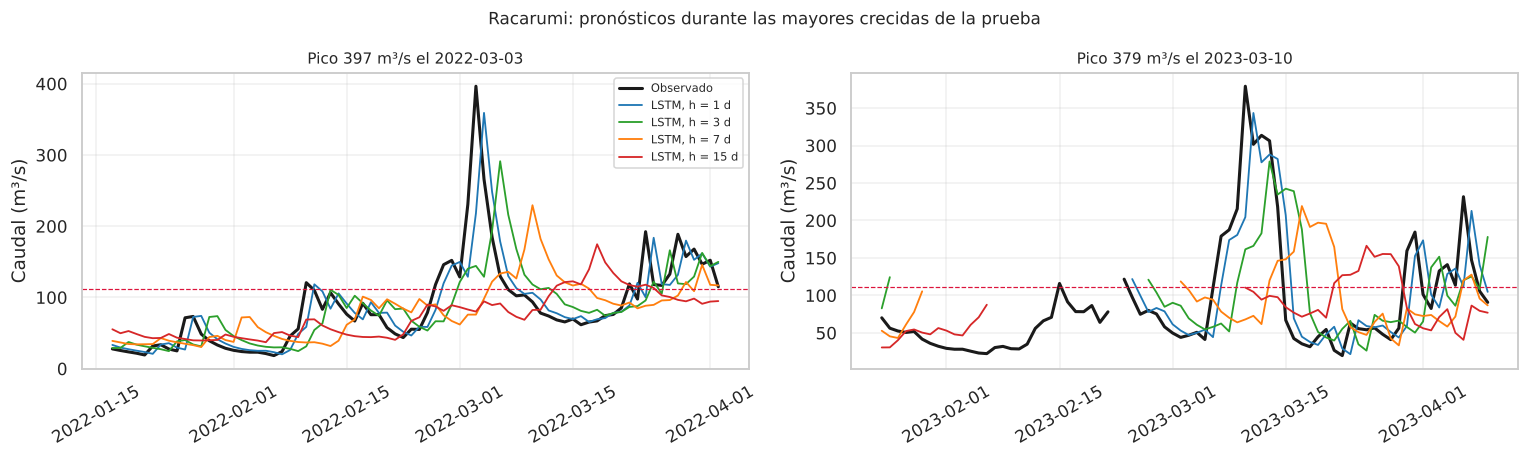

In [20]:
top = EV.sort_values('pico', ascending=False).head(2)
serie_pred = {h: pd.Series(PRED[MEJOR][:, h - 1], index=fechas_p + pd.Timedelta(days=h)) for h in [1, 3, 7, 15]}
fig, ax = plt.subplots(1, len(top), figsize=(14, 4.2), squeeze=False)
for a, (_, e) in zip(ax[0], top.iterrows()):
    v0, v1 = e['fecha_pico'] - pd.Timedelta(days=45), e['fecha_pico'] + pd.Timedelta(days=30)
    a.plot(q.loc[v0:v1].index, q.loc[v0:v1], color='k', lw=2, label='Observado')
    for h, col in zip([1, 3, 7, 15], ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']):
        s = serie_pred[h].loc[v0:v1].asfreq('D')
        a.plot(s.index, s, color=col, lw=1.2, label=f'{MEJOR}, h = {h} d')
    a.axhline(P95, color='crimson', ls='--', lw=0.8)
    a.set_title(f"Pico {e['pico']:,.0f} m³/s el {e['fecha_pico']:%Y-%m-%d}", fontsize=10)
    a.set_ylabel('Caudal (m³/s)'); a.grid(True, alpha=0.3); a.tick_params(axis='x', rotation=30)
ax[0][0].legend(fontsize=7.5)
fig.suptitle(f'{ESTACION}: pronósticos durante las mayores crecidas de la prueba', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig05_eventos.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación — las crecidas de Racarumi suben en 1–2 días y los pronósticos las reproducen después de que ocurren:**
- **2022-03-03 (397 m³/s):** el pronóstico de la LSTM para el día del pico fue 218 m³/s a 1 día (−45 %); su máximo a 1 día, 359 m³/s, llegó **un día después**.
- **2023-03-10 (379 m³/s):** el mismo patrón: 205 m³/s a 1 día para el pico y un máximo de 344 m³/s un día después.
- **Hipótesis explicativa (no probada aquí):** el caudal de hoy no contiene la lluvia que inicia la crecida. Este diseño no incluye lluvia, así que no puede medir cuánto mejoraría el pronóstico con ella.

---
## 9. Sensibilidad a la longitud de la historia y al calendario
**XGBoost** (hiperparámetros de la sección 4, una semilla) se reentrena cambiando los días de historia: L = 1, 3, 7, 15, 30 y 60 (con L = 1 solo conoce el caudal de hoy y la fecha), y una variante **L = 30 sin calendario**. Todas usan el mismo conjunto de muestras (el de L = 60) y su propia corrección de retransformación. XGBoost se usa para todos los análisis auxiliares de las dos estaciones (no se elige el modelo según el resultado).
**Cómo leerlo:** mide cuánta **información predictiva** aportan los días antecedentes y el calendario en este experimento. No mide la memoria física de la cuenca.

In [21]:
BASE_MEM = C.BASE_AUX
m60 = C.construir_muestras(q, L=60, H=H, esc=esc, eps=EPS)
p60 = C.particion(m60)
it60, ip60 = np.concatenate([p60['ent'], p60['val']]), p60['pru']
obs60, pers60, clim60 = m60.q_obs[ip60], C.pred_persistencia(m60, ip60), C.pred_climatologia(m60, ip60, C.climatologia(q, hasta=C.FIN_VALIDACION))
mem = {}
for etiqueta, Lm, cal in [('1', 1, True), ('3', 3, True), ('7', 7, True), ('15', 15, True), ('30', 30, True), ('60', 60, True),
                          ('30 sin calendario', 30, False)]:
    sub = C.Muestras(fechas=m60.fechas, ventana=m60.ventana[:, -Lm:], doy=m60.doy, zt=m60.zt, y=m60.y,
                     q_obs=m60.q_obs, q_t=m60.q_t, eps=m60.eps, L=Lm)
    Xm, _ = C.matriz_tabular(sub, calendario=cal)
    mod = C.crear_tabular(BASE_MEM, mejores[BASE_MEM]).fit(Xm[p60['ent']], sub.y[p60['ent']])
    fac = np.mean(np.exp(sub.y[p60['val']] - mod.predict(Xm[p60['val']])), axis=0)
    mod = C.crear_tabular(BASE_MEM, mejores[BASE_MEM]).fit(Xm[it60], sub.y[it60])
    mem[etiqueta] = C.tabla_metricas(obs60, C.a_caudal(sub, mod.predict(Xm[ip60]), ip60, fac), pers60, clim60)
memoria = pd.concat(mem, names=['L', 'h']).reset_index()
memoria.to_csv(RUTA_TAB / 'tabla_memoria.csv', index=False)
print(f'Modelo usado: {BASE_MEM} | muestras de prueba comunes: {len(ip60)}')
memoria[memoria['h'].isin([1, 3, 7, 15, 30])].pivot(index='L', columns='h', values='hab_pers').reindex(list(mem)).round(3).add_prefix('hab. pers. h=')

Modelo usado: XGBoost | muestras de prueba comunes: 2521


h,hab. pers. h=1,hab. pers. h=3,hab. pers. h=7,hab. pers. h=15,hab. pers. h=30
L,,,,,
1,0.099,0.211,0.343,0.402,0.530
3,0.120,0.212,0.336,0.403,0.528
7,0.120,0.184,0.320,0.399,0.523
15,0.122,0.198,0.329,0.396,0.525
30,0.130,0.204,0.331,0.386,0.527
60,0.119,0.196,0.323,0.409,0.524
30 sin calendario,0.106,0.174,0.269,0.291,0.310


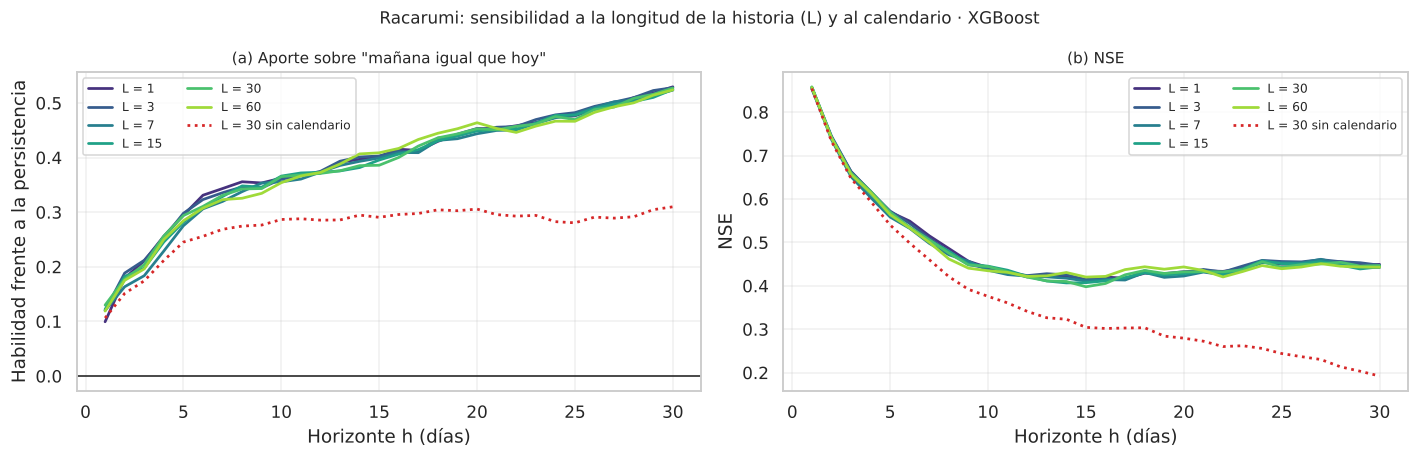

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
pal = sns.color_palette('viridis', 6)
for (et, t), col in zip(mem.items(), list(pal) + ['#d62728']):
    ls = ':' if 'sin' in et else '-'
    ax[0].plot(hh, t['hab_pers'], color=col, lw=1.8, ls=ls, label=f'L = {et}')
    ax[1].plot(hh, t['NSE'], color=col, lw=1.8, ls=ls, label=f'L = {et}')
ax[0].axhline(0, color='k', lw=1)
ax[0].set_ylabel('Habilidad frente a la persistencia'); ax[1].set_ylabel('NSE')
for a, ti in zip(ax, ['(a) Aporte sobre "mañana igual que hoy"', '(b) NSE']):
    a.set_xlabel('Horizonte h (días)'); a.set_title(ti, fontsize=10); a.grid(True, alpha=0.3); a.legend(fontsize=8, ncol=2)
fig.suptitle(f'{ESTACION}: sensibilidad a la longitud de la historia (L) y al calendario · {BASE_MEM}', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig06_memoria.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación — más historia casi no agrega información; el calendario sí (XGBoost):**
- Con **L = 1** (caudal de hoy y fecha) la habilidad frente a la persistencia ya es 0.10 a 1 día, 0.34 a 7 días, 0.40 a 15 días y 0.53 a 30 días. Con L = 3 a 60 cambia ≤ 0.03.
- **Sin calendario** (L = 30) la habilidad cae a 0.27 a 7 días, 0.29 a 15 días y 0.31 a 30 días, y el NSE a 30 días baja de 0.45 a 0.19: a horizontes largos la estacionalidad es casi toda la información aprovechable.
- **Cómo leerlo:** mide la información predictiva de los caudales antecedentes en este experimento, no la memoria física de la cuenca.

---
## 10. Variables más usadas por el modelo
**Importancia por permutación de grupos:** en el XGBoost final (semilla 42) se permutan juntas las columnas de cada grupo en la prueba y se mide cuánto aumenta el error (MSE en m³/s) en h = 1, 3, 7, 15 y 30. Mide cuánto **usa** el modelo cada grupo; con variables correlacionadas no demuestra causalidad.

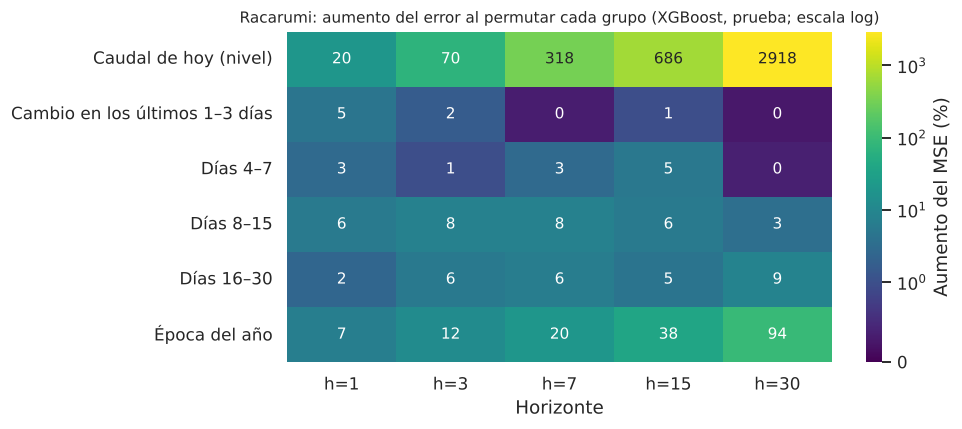

,h=1,h=3,h=7,h=15,h=30
grupo,,,,,
Caudal de hoy (nivel),19.8,70.2,318.4,685.5,2917.6
Cambio en los últimos 1–3 días,4.7,1.6,0.3,1.0,0.3
Días 4–7,2.8,1.0,2.8,5.3,0.4
Días 8–15,5.8,7.6,7.6,5.6,3.5
Días 16–30,2.5,5.6,6.4,4.5,8.7
Época del año,6.7,12.2,19.6,38.1,94.2


In [23]:
imp = C.importancia_grupos(MODELO_AUX, X[idx_p], OBS, m, idx_p, C.grupos_variables(nombres), [1, 3, 7, 15, 30], FACTOR[C.BASE_AUX])
imp.to_csv(RUTA_TAB / 'tabla_importancia.csv')
from matplotlib.colors import SymLogNorm
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(imp * 100, annot=True, fmt='.0f', cmap='viridis', ax=ax, cbar_kws={'label': 'Aumento del MSE (%)'},
            norm=SymLogNorm(linthresh=1, vmin=0, vmax=max(float((imp * 100).max().max()), 10)))
ax.set_xlabel('Horizonte'); ax.set_ylabel('')
ax.set_title(f'{ESTACION}: aumento del error al permutar cada grupo ({C.BASE_AUX}, prueba; escala log)', fontsize=10)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig07_importancia.png', dpi=200, bbox_inches='tight'); plt.show()
(imp * 100).round(1)

**Interpretación (XGBoost):**
- **El nivel de hoy es lo más usado en todos los horizontes:** sin él el error aumenta 20 % a 1 día, 70 % a 3 días y 318 % a 7 días.
- **La época del año gana peso con el horizonte** (+7 % a 1 día, +20 % a 7 días, +94 % a 30 días).
- **La tendencia de los últimos 1–3 días solo aporta a 1 día** (+5 %); los días 4–30, ≤ 9 %. Con variables correlacionadas esto describe el uso del modelo, no causas.

---
## 11. Estabilidad temporal: validación con varios orígenes y selección interna
El protocolo completo se repite con cuatro orígenes temporales. Para cada uno, **todo** se decide con el pasado del origen: ε, umbral de escalones, P95, climatologías, mallas de hiperparámetros (validación interna de 7 años, con calibración en sus 3 primeros años y selección en los 4 últimos, igual que el protocolo principal), épocas de la LSTM (bloque de parada interno), semillas y corrección de retransformación.

| Prueba | Entrenamiento interno | Validación interna |
|---|---|---|
| 1995–2001 | inicio–1987 | 1988–1994 |
| 2002–2008 | inicio–1994 | 1995–2001 |
| 2009–2015 | inicio–2001 | 2002–2008 |
| 2016–fin | inicio–2008 | 2009–2015 (es el protocolo principal: se reutilizan sus resultados) |

Se evalúan la regresión lineal, XGBoost, la LSTM y el modelo seleccionado en la sección 5 (si es otro). Un origen se omite si su entrenamiento interno tiene menos de 1 000 muestras o su validación interna no permite los dos bloques.

In [24]:
CORTES = [('1995–2001', '1987-12-31', '1994-12-31', '2001-12-31'), ('2002–2008', '1994-12-31', '2001-12-31', '2008-12-31'),
          ('2009–2015', '2001-12-31', '2008-12-31', '2015-12-31')]
modelos_est = list(dict.fromkeys(['Regresión lineal', C.BASE_AUX, 'LSTM', MEJOR]))
filas_f, curvas_f = [], {}

def fila_origen(nombre_c, n, t, hz, info_c, params):
    return {'prueba': nombre_c, 'modelo': n, **info_c, 'parámetros elegidos': json.dumps(params), **C.fila_h(hz),
            **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}}

for nombre_c, fe_c, fv_c, fp_c in CORTES:
    eps_c, esc_c = C.eps_entrenamiento(q, fe_c), C.escalones(q, fe_c)
    mc = C.construir_muestras(q, L=L, H=H, esc=esc_c, eps=eps_c)
    pc = C.particion(mc, fe_c, fv_c, fp_c)
    if len(pc['ent']) < 1000 or len(pc['val']) < 300 or len(pc['pru']) < 300:
        print(f"{nombre_c}: se omite (entrenamiento {len(pc['ent'])}, validación {len(pc['val'])}, prueba {len(pc['pru'])} muestras)"); continue
    P95_c = float(np.nanpercentile(q.loc[:fe_c], 95))
    Xc, _ = C.matriz_tabular(mc)
    ec, vc, tc = pc['ent'], pc['val'], pc['pru']
    itc = np.concatenate([ec, vc])
    o, pe = mc.q_obs[tc], C.pred_persistencia(mc, tc)
    pcl = C.pred_climatologia(mc, tc, C.climatologia(q, hasta=fv_c))
    try:
        VCc = C.ValidacionCausal(mc, vc, fe_c)
    except ValueError as err:
        print(f'{nombre_c}: se omite ({err})'); continue
    ov, aq = VCc.obs_sel, VCc.a_q
    info_c = {'muestras ent.': len(ec), 'muestras val.': len(vc), 'muestras prueba': len(tc), 'escalones': len(esc_c),
              'días altos prueba (P95 propio)': int((o[:, 0] > P95_c).sum()),
              'NSE pers. h=7': C.nse(o[:, 6], pe[:, 6]), 'NSE clim. h=7': C.nse(o[:, 6], pcl[:, 6])}
    fin_par_c = str((pd.Timestamp(fe_c) - pd.DateOffset(years=4)).date())
    ec_in = ec[mc.fechas[ec] + pd.Timedelta(days=H) <= pd.Timestamp(fin_par_c)]
    ec_par = ec[mc.fechas[ec] > pd.Timestamp(fin_par_c)]
    for n in modelos_est:
        t0 = time.time()
        semillas = C.SEMILLAS if n in C.ESTOCASTICOS else [C.SEMILLA]
        if n == 'LSTM':
            mejor_p, mejor_v = None, -np.inf
            for params in C.combinaciones(C.MALLAS['LSTM']):
                v = C.nse_medio(aq(C.LSTMProtocolo(mc, ec_in, ec_par, **params).ajustar(ec).predecir(vc)), ov)
                if v > mejor_v:
                    mejor_p, mejor_v = params, v
            yv_s, yp_s = [], []
            for s in semillas:
                lp = C.LSTMProtocolo(mc, ec_in, ec_par, semilla=s, **mejor_p).ajustar(ec)
                yv_s.append(lp.predecir(vc)); yp_s.append(lp.reajustar(itc).predecir(tc))
        else:
            sub = C.ajustar_malla(n, Xc[ec], mc.y[ec], Xc[vc], aq, ov)
            mejor_p = json.loads(max(sub, key=lambda f: f['NSE_val'])['parametros'])
            yv_s = [C.crear_tabular(n, mejor_p, s).fit(Xc[ec], mc.y[ec]).predict(Xc[vc]) for s in semillas]
            yp_s = [C.crear_tabular(n, mejor_p, s).fit(Xc[itc], mc.y[itc]).predict(Xc[tc]) for s in semillas]
        fac = C.factor_duan(mc.y[vc], np.mean(yv_s, 0))
        pr = C.a_caudal(mc, np.mean(yp_s, 0), tc, fac)
        t = C.tabla_metricas(o, pr, pe, pcl)
        hz = C.horizontes(t, C.bootstrap_curvas(mc.fechas[tc], o, pr, pe, pcl, B=min(B, 500)))
        curvas_f[(nombre_c, n)] = t
        filas_f.append(fila_origen(nombre_c, n, t, hz, info_c, mejor_p))
        print(f"{nombre_c} {n:22s} H cota {hz['H_cota']:2d} | H puntual {hz['H_puntual']:2d} | {time.time() - t0:5.0f} s | {mejor_p}")
# origen 2016–fin = protocolo principal (mismas reglas, ya calculado)
info_p = {'muestras ent.': len(ie), 'muestras val.': len(iv), 'muestras prueba': len(idx_p), 'escalones': len(esc),
          'días altos prueba (P95 propio)': int((OBS[:, 0] > P95).sum()),
          'NSE pers. h=7': ref.loc[7, 'NSE persistencia'], 'NSE clim. h=7': ref.loc[7, 'NSE climatología']}
for n in modelos_est:
    curvas_f[('2016–fin', n)] = TAB[n]
    filas_f.append(fila_origen('2016–fin', n, TAB[n], C.horizontes(TAB[n], CURVAS[n]), info_p, mejores[n]))
estab = pd.DataFrame(filas_f)
estab.to_csv(RUTA_TAB / 'tabla_estabilidad_temporal.csv', index=False)
estab.drop(columns=['parámetros elegidos']).round(3)

1995–2001 Regresión lineal       H cota 21 | H puntual 30 |     0 s | {}


1995–2001 XGBoost                H cota 13 | H puntual 28 |   168 s | {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 10.0, 'n_estimators': 100}


1995–2001 LSTM                   H cota 19 | H puntual 30 |    29 s | {'oculto': 64, 'dropout': 0.0}
2002–2008 Regresión lineal       H cota  9 | H puntual 15 |     0 s | {}


2002–2008 XGBoost                H cota  7 | H puntual 14 |   197 s | {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 10.0, 'n_estimators': 200}


2002–2008 LSTM                   H cota 10 | H puntual 17 |    42 s | {'oculto': 32, 'dropout': 0.2}
2009–2015 Regresión lineal       H cota  6 | H puntual 23 |     0 s | {}


2009–2015 XGBoost                H cota  6 | H puntual 16 |   209 s | {'max_depth': 3, 'learning_rate': 0.05, 'reg_lambda': 1.0, 'n_estimators': 200}


2009–2015 LSTM                   H cota 11 | H puntual 24 |    48 s | {'oculto': 32, 'dropout': 0.0}


,prueba,modelo,muestras ent.,muestras val.,muestras prueba,escalones,días altos prueba (P95 propio),NSE pers. h=7,NSE clim. h=7,H puntual (d),...,H p05 (d),H mediana (d),H p95 (d),P(H ≥ 30),H marginal estricto (d),NSE ≥ 0.5 hasta (d),NSE h=1,NSE h=7,NSE h=15,NSE h=30
0,1995–2001,Regresión lineal,2227,2321,2302,0,179,0.506,0.427,30,...,21,30,30,0.668,20,19,0.893,0.620,0.523,0.439
1,1995–2001,XGBoost,2227,2321,2302,0,179,0.506,0.427,28,...,13,25,30,0.416,11,14,0.897,0.617,0.495,0.419
2,1995–2001,LSTM,2227,2321,2302,0,179,0.506,0.427,30,...,19,30,30,0.618,15,21,0.896,0.632,0.534,0.455
3,2002–2008,Regresión lineal,4578,2302,2368,0,156,0.444,0.482,15,...,9,15,23,0.020,8,14,0.896,0.578,0.491,0.395
4,2002–2008,XGBoost,4578,2302,2368,0,156,0.444,0.482,14,...,7,14,19,0.002,6,13,0.896,0.557,0.477,0.329
5,2002–2008,LSTM,4578,2302,2368,0,156,0.444,0.482,17,...,10,17,30,0.078,9,15,0.896,0.591,0.515,0.384
6,2009–2015,Regresión lineal,6910,2368,2371,0,177,0.363,0.483,23,...,6,22,30,0.258,6,17,0.892,0.547,0.509,0.442
7,2009–2015,XGBoost,6910,2368,2371,0,177,0.363,0.483,16,...,6,16,30,0.064,6,11,0.894,0.552,0.476,0.399
8,2009–2015,LSTM,6910,2368,2371,0,177,0.363,0.483,24,...,11,23,30,0.222,9,19,0.891,0.578,0.523,0.444
9,2016–fin,Regresión lineal,9308,2371,2521,0,148,0.262,0.460,7,...,5,8,22,0.020,4,6,0.847,0.483,0.424,0.448


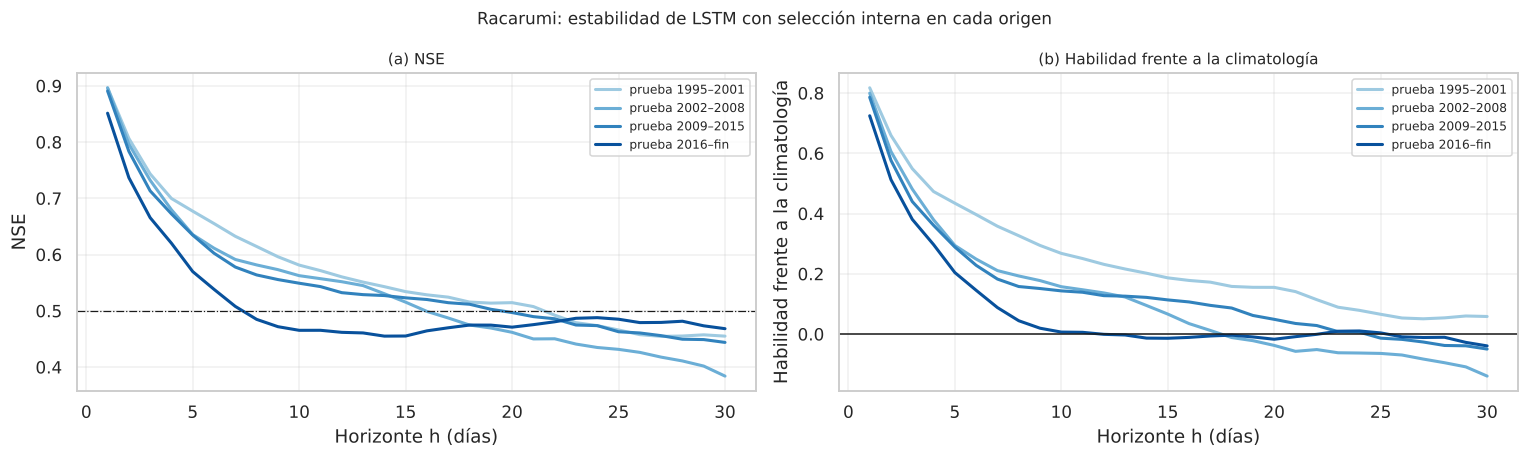

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
orden = ['1995–2001', '2002–2008', '2009–2015', '2016–fin']
pal = dict(zip(orden, ['#9ecae1', '#6baed6', '#3182bd', '#08519c']))
for (nombre_c, n), t in curvas_f.items():
    if n == MEJOR:
        ax[0].plot(hh, t['NSE'], color=pal[nombre_c], lw=2, label=f'prueba {nombre_c}')
        ax[1].plot(hh, t['hab_clim'], color=pal[nombre_c], lw=2, label=f'prueba {nombre_c}')
ax[0].axhline(0.5, color='k', lw=0.8, ls='-.'); ax[1].axhline(0, color='k', lw=1)
ax[0].set_ylabel('NSE'); ax[1].set_ylabel('Habilidad frente a la climatología')
for a, ti in zip(ax, ['(a) NSE', '(b) Habilidad frente a la climatología']):
    a.set_xlabel('Horizonte h (días)'); a.set_title(ti, fontsize=10); a.grid(True, alpha=0.3); a.legend(fontsize=8)
fig.suptitle(f'{ESTACION}: estabilidad de {MEJOR} con selección interna en cada origen', fontsize=11)
fig.tight_layout(); fig.savefig(RUTA_FIG / 'fig08_estabilidad.png', dpi=200, bbox_inches='tight'); plt.show()

**Interpretación — con selección interna en cada origen, 2016–fin es el periodo más difícil:**
- **LSTM (H cota 95 %):** 19, 10, 11 y 6 días en 1995–2001, 2002–2008, 2009–2015 y 2016–fin. Regresión lineal: 21, 9, 6 y 5; XGBoost: 13, 7, 6 y 5.
- **El horizonte depende mucho del periodo:** en 1995–2001 la estimación puntual llega a ≥ 30 días y el NSE ≥ 0.5 a 14–21 días; en 2016–fin, a 7–11 y 6–7 días. La persistencia también empeora (NSE a 7 días de 0.51 a 0.26): el periodo de prueba principal tiene crecidas más difíciles de seguir.
- **Conclusión:** 6 días es la cota del periodo más reciente, no un valor fijo de la estación; con otros años llega a 10–19 días con la LSTM. Como en cada origen todo se eligió con su propio pasado (también la calibración en dos bloques), esta variación no se debe a decisiones tomadas con años posteriores.

---
## 12. Sensibilidad a los registros con escalones de nivel
Si la estación tiene escalones, el entrenamiento se repite usando **solo los años sin escalones** (un año se excluye si tiene un escalón) y se evalúa en la misma prueba. Como control, XGBoost se repite **20 veces** con la misma cantidad de años de entrenamiento elegidos al azar **entre los años con escalones** y la misma validación. Para que sean comparables, XGBoost se ajusta con una sola semilla (42) en la referencia con todos los años, en la variante restringida y en los controles.
**Cómo leerlo:** es un análisis de **sensibilidad**, no una prueba de causa. Las variantes difieren a la vez en cantidad de datos, décadas cubiertas y tipos de eventos; por eso se describen los años usados y se ubica la variante restringida dentro de la distribución de los controles. Los hiperparámetros son los de la sección 4.

In [26]:
N_CONTROL = 3 if RAPIDO else 20
if len(esc) == 0:
    sens, sens_resumen = pd.DataFrame(), pd.DataFrame()
    print('Esta estación no tiene escalones de nivel: el análisis no aplica.')
else:
    anios_malos = sorted(set(esc.year))
    permitidos = pd.Series(~q.index.year.isin(anios_malos), index=q.index)
    libres = sorted(set(q.index.year[permitidos & (q.index <= C.FIN_VALIDACION)]))
    print(f'Años con escalón ({len(anios_malos)}): {anios_malos[0]}–{anios_malos[-1]} | años sin escalón hasta 2015: {libres}')
    def variante(perm, n, etiqueta, anios, una_semilla=False):
        ms = C.construir_muestras(q, L=L, H=H, esc=esc, eps=EPS, permitidos=perm)
        ps = C.particion(ms)
        assert (ms.fechas[ps['pru']] == fechas_p).all(), 'la prueba debe ser idéntica'
        Xs, _ = C.matriz_tabular(ms)
        its = np.concatenate([ps['ent'], ps['val']])
        semillas = C.SEMILLAS if (n in C.ESTOCASTICOS and not una_semilla) else [C.SEMILLA]
        if n == 'LSTM':
            e_in = ps['ent'][ms.fechas[ps['ent']] + pd.Timedelta(days=H) <= pd.Timestamp(C.FIN_PARADA)]
            e_par = ps['ent'][ms.fechas[ps['ent']] > pd.Timestamp(C.FIN_PARADA)]
            yv_s, yp_s = [], []
            for s in semillas:
                lp = C.LSTMProtocolo(ms, e_in, e_par, semilla=s, **mejores['LSTM']).ajustar(ps['ent'])
                yv_s.append(lp.predecir(ps['val'])); yp_s.append(lp.reajustar(its).predecir(ps['pru']))
        else:
            yv_s = [C.crear_tabular(n, mejores[n], s).fit(Xs[ps['ent']], ms.y[ps['ent']]).predict(Xs[ps['val']]) for s in semillas]
            yp_s = [C.crear_tabular(n, mejores[n], s).fit(Xs[its], ms.y[its]).predict(Xs[ps['pru']]) for s in semillas]
        fac = np.mean(np.exp(ms.y[ps['val']] - np.mean(yv_s, 0)), axis=0)
        t = C.tabla_metricas(OBS, C.a_caudal(ms, np.mean(yp_s, 0), ps['pru'], fac), PERS, CLIM)
        hz = C.horizontes(t, C.bootstrap_curvas(fechas_p, OBS, C.a_caudal(ms, np.mean(yp_s, 0), ps['pru'], fac), PERS, CLIM, B=min(B, 500)))
        return {'modelo': n, 'entrenamiento': etiqueta, 'años de entrenamiento': anios, 'muestras ent.': len(ps['ent']),
                **C.fila_h(hz), **{f'NSE h={h}': t.loc[h, 'NSE'] for h in (1, 7, 15, 30)}, 'hab. clim. h=30': t.loc[30, 'hab_clim']}
    filas_s = []
    todos_anios = pd.Series(True, index=q.index)
    filas_s.append(variante(todos_anios, C.BASE_AUX, 'todos los años (una semilla)', 'todos', una_semilla=True))
    filas_s.append(variante(permitidos, C.BASE_AUX, 'solo años sin escalones', ', '.join(str(a) for a in libres if a <= 2008), una_semilla=True))
    if MEJOR != C.BASE_AUX:
        hz0 = C.horizontes(TAB[MEJOR], CURVAS[MEJOR])
        filas_s.append({'modelo': MEJOR, 'entrenamiento': 'todos los años (principal)', 'años de entrenamiento': 'todos',
                        'muestras ent.': len(ie), **C.fila_h(hz0), **{f'NSE h={h}': TAB[MEJOR].loc[h, 'NSE'] for h in (1, 7, 15, 30)},
                        'hab. clim. h=30': TAB[MEJOR].loc[30, 'hab_clim']})
        filas_s.append(variante(permitidos, MEJOR, 'solo años sin escalones', ', '.join(str(a) for a in libres if a <= 2008)))
    rng_c = np.random.default_rng(C.SEMILLA)
    n_ent = sum(1 for a in libres if a <= 2008)
    malos_ent = [a for a in anios_malos if a <= 2008]
    val_libre = sorted(set(q.index.year[permitidos & (q.index > C.FIN_ENTRENAMIENTO)]))   # validación y prueba sin escalones (idénticas)
    for r_ in range(N_CONTROL):
        elegidos = sorted(int(a) for a in rng_c.choice(malos_ent, n_ent, replace=False))
        perm_c = pd.Series(q.index.year.isin(elegidos) | q.index.year.isin(val_libre), index=q.index)
        filas_s.append(variante(perm_c, C.BASE_AUX, f'control {r_ + 1}', ', '.join(map(str, elegidos)), una_semilla=True))
    sens = pd.DataFrame(filas_s)
    ctrl = sens[sens['entrenamiento'].str.startswith('control')]
    restr = sens[(sens['modelo'] == C.BASE_AUX) & (sens['entrenamiento'] == 'solo años sin escalones')].iloc[0]
    ref_s = sens[(sens['modelo'] == C.BASE_AUX) & (sens['entrenamiento'] == 'todos los años (una semilla)')].iloc[0]
    cols_r = ['H cota 95 % (d)', 'H puntual (d)', 'NSE h=7', 'NSE h=30', 'muestras ent.']
    sens_resumen = pd.DataFrame({'todos los años': ref_s[cols_r], 'solo años sin escalones': restr[cols_r],
                                 'controles: mínimo': ctrl[cols_r].min(), 'p25': ctrl[cols_r].quantile(0.25),
                                 'mediana': ctrl[cols_r].median(), 'p75': ctrl[cols_r].quantile(0.75), 'máximo': ctrl[cols_r].max(),
                                 'controles ≤ variante restringida (%)': [100 * (ctrl[c_] <= restr[c_]).mean() for c_ in cols_r]})
    sens_resumen.to_csv(RUTA_TAB / 'tabla_sensibilidad_registros_resumen.csv')
sens.to_csv(RUTA_TAB / 'tabla_sensibilidad_registros.csv', index=False)
sens_resumen.round(3) if len(sens_resumen) else sens

Esta estación no tiene escalones de nivel: el análisis no aplica.


""


**Interpretación:** no aplica. Racarumi no tiene escalones de nivel.

---
## 13. Síntesis y archivos para la comparación
Archivos que usan los cuadernos siguientes: el resumen (`resumen.json`), los pronósticos de validación y prueba (`predicciones.npz`, que usan los cuadernos 03 y 04 y la página interactiva) y una tabla larga de prueba con estación, modelo, emisión, fecha objetivo, horizonte, observado, pronosticado y calidad de la entrada (`predicciones_prueba_largo.csv.gz`).

In [27]:
resumen_est = dict(
    version=C.VERSION, revision=C.REVISION, rapido=RAPIDO, estacion=ESTACION, cuenca=C.ESTACIONES[ESTACION]['cuenca'], vertiente=C.ESTACIONES[ESTACION]['vertiente'],
    periodo=f"{info['inicio']:%Y-%m-%d} a {info['fin']:%Y-%m-%d}", P95=P95, eps=EPS, mejor_modelo=MEJOR, mayor_nse=MAS_ALTO,
    base_aux=C.BASE_AUX, validacion=VC.resumen(), seleccion=SELEC.reset_index().to_dict(orient='records'),
    mejores_parametros=mejores, epocas_lstm=mejor_lstm.get('epocas'), nse_val=NSE_VAL,
    combinado={str(h): ELEGIDO[h] for h in C.HORIZONTES},
    horizonte=hu_tab.reset_index().to_dict(orient='records'), horizonte_comun=hu_c.reset_index().to_dict(orient='records'),
    fechas_comunes=dict(n=int(len(FC)), inicio=str(FC.min().date()), fin=str(FC.max().date())),
    muestras={k: int(len(v)) for k, v in p.items()}, inventario=m.info, escalones=int(len(esc)), excluidas_escalon=int(m.excluidas_escalon),
    semillas=C.SEMILLAS, minutos=round((time.time() - T_INICIO) / 60, 1))
(RUTA_SAL / 'resumen.json').write_text(json.dumps(resumen_est, ensure_ascii=False, indent=1, default=float), encoding='utf-8')
dias = lambda f: (f - pd.Timestamp('1970-01-01')).days.to_numpy()
np.savez_compressed(RUTA_SAL / 'predicciones.npz',
    modelos=np.array(TODOS), fechas_val=dias(m.fechas[iv]), fechas_sel=dias(VC.fechas_sel), fechas_pru=dias(fechas_p),
    obs_val=m.q_obs[iv].astype(np.float32), obs_sel=OBS_V.astype(np.float32), obs_pru=OBS.astype(np.float32),
    pers_pru=PERS.astype(np.float32), clim_pru=CLIM.astype(np.float32),
    pers_val=C.pred_persistencia(m, iv).astype(np.float32), clim_val=C.pred_climatologia(m, iv, CLIM_E).astype(np.float32),
    interp_val=m.interpolada[iv], interp_pru=m.interpolada[idx_p],
    **{f'sel_{i}': PRED_V[n].astype(np.float32) for i, n in enumerate(TODOS)},        # media, bloque de selección
    **{f'valmed_{i}': PRED_MED_V[n].astype(np.float32) for i, n in enumerate(TODOS)},  # mediana, toda la validación
    **{f'pru_{i}': PRED[n].astype(np.float32) for i, n in enumerate(TODOS)},           # media (Duan), prueba
    **{f'prumed_{i}': PRED_MED[n].astype(np.float32) for i, n in enumerate(TODOS)})    # mediana, prueba
dec = 0 if P95 > 1000 else 2
bloques_largo = []
for n, arr in [*((n, PRED[n]) for n in TODOS), ('Persistencia', PERS), ('Climatología', CLIM)]:
    bloques_largo.append(pd.DataFrame({'estacion': ESTACION, 'modelo': n, 'semillas': 'promedio de ' + str(len(C.SEMILLAS)) if n in C.ESTOCASTICOS else 'única',
        'corte': 'principal', 'emision': np.repeat(fechas_p.date, H), 'h': np.tile(np.arange(1, H + 1), len(fechas_p)),
        'observado': OBS.ravel().round(dec), 'pronosticado': arr.ravel().round(dec),
        'entrada_interpolada': np.repeat(m.interpolada[idx_p], H)}))
largo_p = pd.concat(bloques_largo, ignore_index=True)
largo_p.insert(5, 'objetivo', pd.to_datetime(largo_p['emision']) + pd.to_timedelta(largo_p['h'], unit='D'))
largo_p.to_csv(RUTA_SAL / 'predicciones_prueba_largo.csv.gz', index=False, compression='gzip')
print('Guardado:', (RUTA_SAL / 'predicciones.npz').stat().st_size // 1024, 'kB (npz) |',
      (RUTA_SAL / 'predicciones_prueba_largo.csv.gz').stat().st_size // 1024, 'kB (tabla larga) |', f'{resumen_est["minutos"]} min')
hu_tab[['H cota 95 % (d)', 'H puntual (d)', 'H p05 (d)', 'H p95 (d)', 'NSE ≥ 0.5 hasta (d)', 'NSE medio selección']]

Guardado: 6452 kB (npz) | 5326 kB (tabla larga) | 26.6 min


,H cota 95 % (d),H puntual (d),H p05 (d),H p95 (d),NSE ≥ 0.5 hasta (d),NSE medio selección
modelo,,,,,,
Regresión lineal,5,7,5,22,6,0.553134
Random Forest,6,11,6,29,7,0.536527
XGBoost,5,8,5,19,7,0.532080
KNN,4,6,4,12,5,0.532315
MLP,6,14,6,30,7,0.545783
LSTM,6,11,6,30,7,0.559877
Combinado por horizonte,6,11,6,20,7,NaN


### 13.1 Conclusiones para esta estación

| Pregunta | Resultado en Racarumi |
|---|---|
| ¿Hasta cuántos días es útil el pronóstico de la magnitud? | **6 días** (H cota 95 %, LSTM); 4–6 días según el modelo. En otros orígenes, 10–19 días con la LSTM: 2016–2023 es el periodo más difícil |
| ¿Con calidad suficiente (NSE ≥ 0.5)? | Hasta 5–7 días |
| ¿Qué modelo elegir? | La regla selecciona la **LSTM** (mayor NSE de selección), pero su ventaja sobre la regresión lineal, la MLP, Random Forest y KNN es **inconclusa**; solo XGBoost es peor. La regresión lineal es una alternativa práctica con 1 día menos de cota |
| ¿Y en crecidas? | Subestima todos los picos (−43 % el día del pico a 1 día) y en la mayoría de los eventos reproduce el máximo h días después de ocurrido |
| ¿Qué información usa? | El nivel de hoy y la época del año; la historia de días anteriores casi no agrega y el calendario es decisivo a horizontes largos |

**Implicaciones:** en esta cuenca rápida, el caudal antecedente y el calendario dan alrededor de una semana de pronóstico útil de la **magnitud**; si permiten avisar el **inicio** de una crecida se evalúa en el cuaderno 04. Los resultados se refieren a esta estación y este periodo.

---
## 14. Referencias
- Llauca, H., Montesinos-Caceres, C., Gutierrez-Reynaga, M. y Lavado-Casimiro, W. (2026). CAMELS-PE: Hydrometeorological time series and catchment attributes for 136 catchments in Peru. *Earth System Science Data Discussions*. https://doi.org/10.5194/essd-2026-386
- Chen, T. y Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD*, 785–794.
- Duan, N. (1983). Smearing estimate: a nonparametric retransformation method. *Journal of the American Statistical Association*, 78(383), 605–610.
- Gupta, H. V., Kling, H., Yilmaz, K. K. y Martinez, G. F. (2009). Decomposition of the mean squared error and NSE performance criteria. *Journal of Hydrology*, 377, 80–91.
- Hochreiter, S. y Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735–1780.
- Kratzert, F., Klotz, D., Brenner, C., Schulz, K. y Herrnegger, M. (2018). Rainfall–runoff modelling using Long Short-Term Memory (LSTM) networks. *Hydrology and Earth System Sciences*, 22, 6005–6022.
- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics*, 17(3), 1217–1241.
- Lujano, E., Lujano, R., Huamani, J. C. y Lujano, A. (2023). Modelado hidrológico basado en el algoritmo KNN: una aplicación para el pronóstico de caudales diarios del río Ramis, Perú. *Tecnología y Ciencias del Agua*. https://doi.org/10.24850/j-tyca-14-02-05
- Nash, J. E. y Sutcliffe, J. V. (1970). River flow forecasting through conceptual models part I. *Journal of Hydrology*, 10(3), 282–290.
- Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: an analysis and review. *International Journal of Forecasting*, 16(4), 437–450.